# Imports

In [1]:
import os, sys, glob, subprocess
sys.path.append("D:\\DATA\\ActivePIC")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import linecache
from tqdm import tqdm

# Run scan in wavelength and phase

### Passive tricoupler

In [ ]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename, input_config = "Tricoupler_FiberOneInput", 'Center' # offset = (BendOffset+width+TricouplerCoupleSeparation)
filename_root = f'{filename}_{input_config}_RaisedSineSbend'
save_dir = working_dir+f"{filename_root}_scan_Wav_CouplingLength"
filename = f"{filename}.ind"

wav_arr = np.linspace(1.45, 1.65, 51)
length_arr = np.array([278., 308., 338.])

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for length in tqdm(length_arr, desc=f"Coupling length loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("TricouplerCoupleLength", length)
        c.write(working_dir+filename)
    
        wav_str = f"{wav:0.3f}".replace(".", "p")
        length_str = f"{length:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_CouplingLength{length_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CouplingLength.npy", length_arr)

Wavelength loop: 0it [00:00, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   0%|                                           | 0/3 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.45 microns): 100%|███████████████████████████████████| 3/3 [01:04<00:00, 21.78s/it]
Wavelength loop: 1it [01:04, 64.97s/it]                                                                                
Coupling length loop (Wavelength: 1.454 microns):   0%|                                          | 0/3 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.454 microns):  33%|███████████▎                      | 1/3 [00:22<00:45, 22.57s/it]
Coupling length loop (Wavelength: 1.454 microns):  67%|██████████████████████▋           | 2/3 [00:46<00:23, 23.10s/it]
Coupling length loop (Wavelength: 1.454 microns): 100%|██████████████████████████████████| 3/3 [01:09<00:00, 23.30s/it]
Wavelength loop: 2it [02:14, 67.70s/it]                                                                                
Coup

In [13]:
np.linspace(3.0, 3.8, 5)

array([3. , 3.2, 3.4, 3.6, 3.8])

In [18]:
coupling_lengths

[278]

In [ ]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberOneInput"
CAD_path = f"{working_dir}{filename_root}.ind"

# Define parameter scan
# wavs = np.linspace(1.45, 1.65, 11)
wavs = np.linspace(1.45, 1.65, 5)[:1]
coupling_lengths = [278, 308, 338][1:]
width_arr = np.linspace(3.2, 3.6, 5)
input_offsets = ['-InputOffset', 0, 'InputOffset'][:1]        # inputs A, B, C

grid_size, grid_edge, step_z = 0.1, 0.5, 0.2
contrast = 1.02

keep_ext = (".mon", ".json", ".dat")                      # keep_ext=None keeps every output file, as your original script did
skip_existing = False                                     # True: skip runs whose .mon file already exists, to resume a scan

for coupling_length in tqdm(coupling_lengths, desc='Coupling length loop', position=0, leave=False):
    save_dir = f"{working_dir}Tricoupler_passive_sim\\{filename_root}_couplingLength{coupling_length}_scan_Wav_Width\\"
    os.makedirs(save_dir, exist_ok=True)                  # Make scan save directory if it doesn't exist
    for wav in tqdm(wavs, desc='Wavelength loop', position=1, leave=False):
        for width in tqdm(width_arr, desc='Width loop', position=2, leave=False):
            for i, input_offset in enumerate(input_offsets):
                input_name = chr(65 + i)
                print(f'Input {input_name}')
                prefix = (f"{save_dir}{filename_root}_couplingLength{coupling_length}_input{input_name}"
                          f"_Width{rlib.param_str(width, 2)}_Wav{rlib.param_str(wav)}")
                if skip_existing and os.path.exists(prefix + ".mon"):
                    continue
                rlib.run_sim(
                    CAD_path,
                    prefix=prefix,
                    symbols={
                        "Grid_Size": grid_size,
                        "Grid_Edge": grid_edge,
                        "Step_z": step_z,
                        "TricouplerCoupleSeparation": 2.0,
                        "TricouplerCoupleLength": coupling_length,
                        "InputInjection": input_offset,
                        "contrast": contrast,
                        "free_space_wavelength": wav,
                        "width": width,
                        "Mode_filename": rlib.mode_field(wav, width, mode_dir=rlib.MODE_LIB_DIR, height=3.4)[0],
                        "pade_order": 2,
                        "pade_order_warning_3d": 0
                    },
                    keep_ext=keep_ext,
                )

    np.save(os.path.join(save_dir, f"{filename_root}_width.npy"), width_arr)
    np.save(os.path.join(save_dir, f"{filename_root}_wav.npy"), wavs)

Coupling length loop:   0%|          | 0/2 [00:00<?, ?it/s]


Input A


KeyboardInterrupt: 

### Active tricoupler

Two-beam nulling

In [44]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename = "Tricoupler_FiberTwoInput"

filename_root = filename
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
filename = f"{filename}.ind"

# wav_arr = np.linspace(1.45, 1.65, 11)
# coupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)
wav_arr = [1.55]
coupleLength_arr = [308]

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for coupleLength in tqdm(coupleLength_arr, desc=f"Coupling length loop (Wavelength: {wav} microns)", position=1, leave=False):
        # Read in circuit, set probe wavelength
        phase = 180
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)
    
        # Read in circuit, set probe wavelength
        phase = 0
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CouplingLength.npy", coupleLength_arr)

Wavelength loop: 0it [00:00, ?it/s]

In [7]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
wav_arr = np.load(f"{save_dir}/{filename_root}_Wav.npy")
coupleLength_arr = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")

outputs_max, outputs_null = [], []
for coupleLength in coupleLength_arr:
    coupleLength_str = f"{coupleLength:0.3f}".replace(".", "p")
    output_max, output_null = [], []
    for wav in wav_arr:
        phase = 0
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_max.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])

        phase = 180
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_null.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])
    outputs_max.append(output_max)
    outputs_null.append(output_null)
outputs_max, outputs_null = np.array(outputs_max), np.array(outputs_null)

In [10]:
np.shape(x), np.shape(y), np.shape(data)

((3000,), (348,), (349, 3000))

Week1/tricoupler_passive_sim/Tricoupler_FiberOneInput_couplingLength278_scan_Contrast/Tricoupler_FiberOneInput_couplingLength278_inputC_TricouplerCoupleSeparation2p00_Wav1p650_Contrast1p024000_GridSize0.1_GridEdge0.1.mon)
Missing file: Week1\tricoupler_passive_sim\Tricoupler_FiberOneInput_couplingLength338_scan_Contrast\Tricoupler_FiberOneInput_couplingLength338_inputC_TricouplerCoupleSeparation2p00_Wav1p450_Contrast1p022800_GridSize0.1_GridEdge0.1.mon


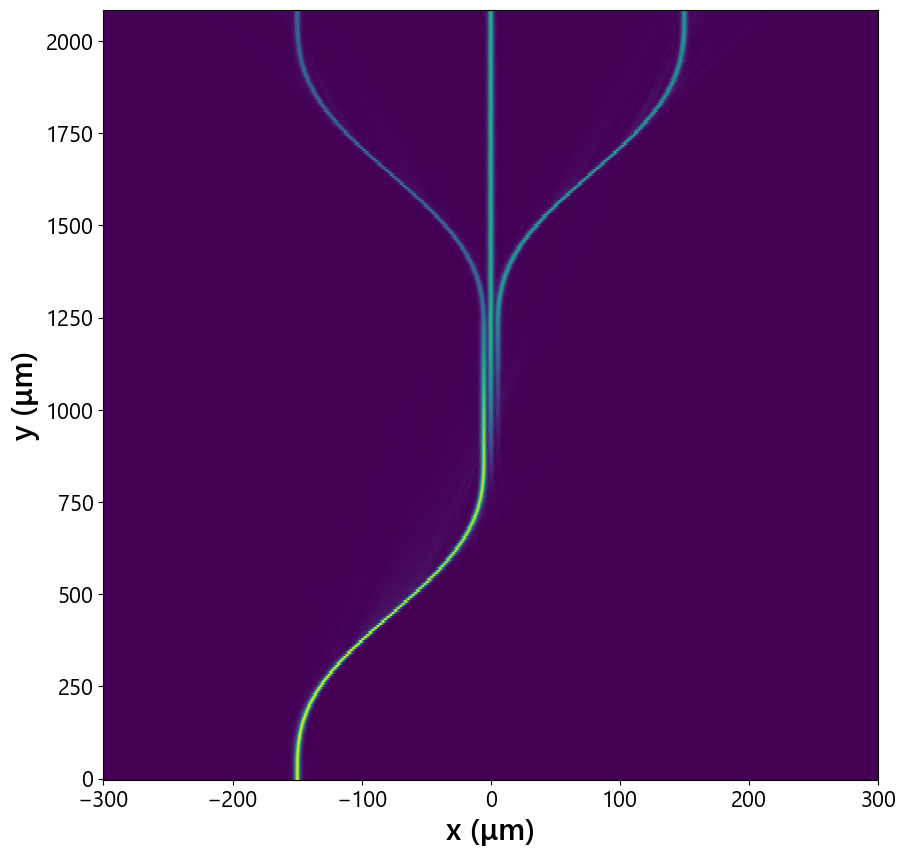

In [15]:
import matplotlib.patches as patches

filename = "D:\\DATA\\SURF_2026\\Week1\\tricoupler_passive_sim\\Tricoupler_FiberOneInput_couplingLength308_scan_Separation\\Tricoupler_FiberOneInput_couplingLength308_inputA_TricouplerCoupleSeparation2p00_Wav1p550_xz.dat"
data = np.genfromtxt(filename, delimiter='', skip_header=6)[:,1:].T
x_line = linecache.getline(filename, 4)
y_line = linecache.getline(filename, 5)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

fig, ax = plt.subplots(figsize=(10,10))
plt.pcolormesh(x, y, data)
# rect = patches.Rectangle([-3.4/2, -3.4/2], 3.4, 3.4, edgecolor='red', facecolor='none', linewidth=2)
# ax.add_patch(rect)
plt.xlabel('x (μm)')
plt.ylabel('y (μm)')
plt.show()

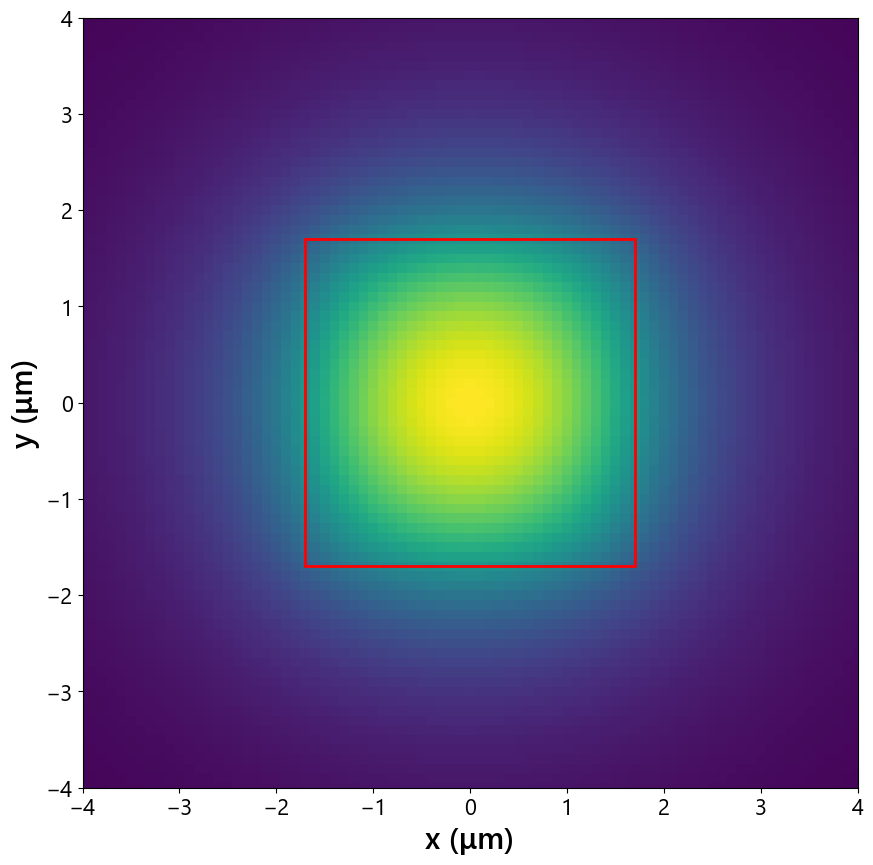

In [28]:
import matplotlib.patches as patches

filename = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\ModeField_ex.m00"
data = np.genfromtxt(filename, delimiter='', skip_header=4).T
x_line = linecache.getline(filename, 3)
y_line = linecache.getline(filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

fig, ax = plt.subplots(figsize=(10,10))
plt.pcolormesh(x, y, data)
rect = patches.Rectangle([-3.4/2, -3.4/2], 3.4, 3.4, edgecolor='red', facecolor='none', linewidth=2)
ax.add_patch(rect)
plt.xlabel('x (μm)')
plt.ylabel('y (μm)')
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.show()

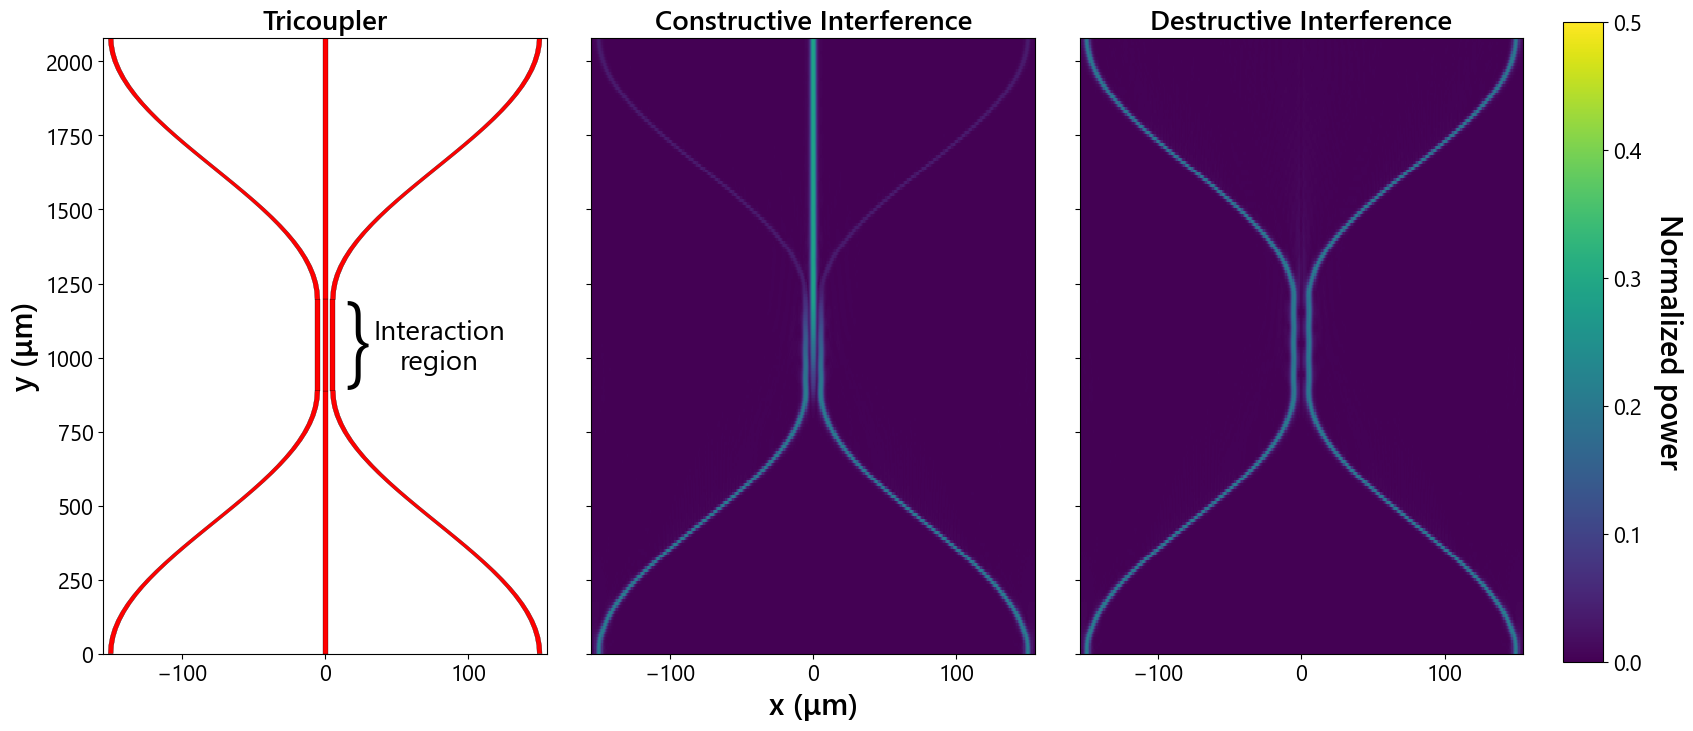

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon, PathPatch
from matplotlib.path import Path
import linecache
import phidl.geometry as pg


working_dir = r"C:\Users\runner\ActivePIC\Tricoupler"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = os.path.join(working_dir, f"{filename_root}_scan_Wav_coupleLength")
gds_filepath = os.path.join(working_dir, f"{filename_root}.gds")

# GDS
layout = pg.import_gds(gds_filepath)

# Constructive interference
filename = os.path.join(save_dir, "Tricoupler_FiberTwoInput_scan_Wav1p550_Phase0p000_CoupleLength308p000_xz.dat")
data_0 = np.genfromtxt(filename, delimiter='', skip_header=6)[:, 1:].T
x_line = linecache.getline(filename, 4)
y_line = linecache.getline(filename, 5)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')

x_0 = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y_0 = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

# Destructive interference
filename = os.path.join(save_dir, "Tricoupler_FiberTwoInput_scan_Wav1p550_Phase180p000_CoupleLength308p000_xz.dat")
data_180 = np.genfromtxt(filename, delimiter='', skip_header=6)[:, 1:].T
x_line = linecache.getline(filename, 4)
y_line = linecache.getline(filename, 5)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x_180 = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y_180 = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))


def curly_brace(ax, x, y1, y2, width=10, lw=0.5):
    ym = (y1 + y2) / 2
    verts = [(x, y1), (x-width, y1), (x-width, ym), (x, ym),
             (x-width, ym), (x-width, y2), (x, y2)]
    codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3, Path.CURVE3,
             Path.CURVE3, Path.CURVE3, Path.CURVE3]
    ax.add_patch(PathPatch(Path(verts, codes), fill=False, lw=lw, clip_on=False))

fig, ax = plt.subplots(1, 3, figsize=(20, 8), sharey=True)
fig.subplots_adjust(left=0.15, right=0.86, wspace=0.1)

patches = [Polygon(poly, closed=True) for poly in layout.get_polygons()]
pc = PatchCollection(patches, facecolor='red', edgecolor='k', linewidth=0.2)
ax[0].add_collection(pc)
ax[0].autoscale()
ax[0].set_ylabel('y (μm)')
ax[0].set_ylim(0, 2080)
ax[0].set_xlim(-190, 155)
ax[0].set_title('Tricoupler')

y1, y2 = 920, 1150
from matplotlib.transforms import Affine2D

brace = ax[0].text(
    23, (y1+y2)/2, '}',
    fontsize=75,
    va='center', ha='center', fontweight='light',
)

ax[0].text(80, (y1+y2)/2, 'Interaction\nregion',
           va='center', ha='center', fontsize=20)

vmax = 0.5
ax[1].pcolormesh(x_0, y_0, data_0, vmin=0, vmax=vmax)
ax[1].set_title('Constructive Interference')

im = ax[2].pcolormesh(x_180, y_180, data_180, vmin=0, vmax=vmax)
ax[2].set_title('Destructive Interference')

# Leave space on the left
cax = fig.add_axes([0.88, 0.1, 0.02, 0.8])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Normalized power', rotation=270, labelpad=30)

ax[1].set_xlabel('x (μm)')
for i in range(3):
    ax[i].set_xlim(-155, 155)

plt.savefig(working_dir+'\\Tricoupler_basics.png', dpi=300,
            bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
wav_arr = np.load(f"{save_dir}/{filename_root}_Wav.npy")

In [21]:
from matplotlib.animation import FuncAnimation, PillowWriter
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Create persistent line objects
lines_null = [ax[0].plot([], [], label=f'Output {c}')[0] for c in ['A', 'B', 'C']]
lines_max  = [ax[1].plot([], [], label=f'Output {c}')[0] for c in ['A', 'B', 'C']]
line_db    = ax[2].plot([], [], 'k')[0]

# Static axis formatting
ax[0].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Nulling condition output', fontsize=14, fontweight='bold')
ax[0].set_xlim(min(wav_arr), max(wav_arr))
ax[0].set_ylim(0, 1)
ax[0].legend()

ax[1].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Constructive condition output', fontsize=14, fontweight='bold')
ax[1].set_xlim(min(wav_arr), max(wav_arr))
ax[1].set_ylim(0, 1)
ax[1].legend()

ax[2].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[2].set_ylabel('Null depth (dB)', fontsize=14, fontweight='bold')
ax[2].set_xlim(min(wav_arr), max(wav_arr))
ax[2].set_ylim(-60, 0)

def update(i):
    # Null outputs
    for j in range(3):
        lines_null[j].set_data(wav_arr, outputs_null[i][:, j])

    # Constructive outputs
    for j in range(3):
        lines_max[j].set_data(wav_arr, outputs_max[i][:, j])

    # Null depth
    db = 10 * np.log10(outputs_null[i][:,1] / outputs_max[i][:,1])
    line_db.set_data(wav_arr, db)

    fig.suptitle(
        f'Coupling length: {coupleLength_arr[i]:.3f} microns',
        fontsize=18,
        fontweight='bold'
    )

    return (*lines_null, *lines_max, line_db)

ani = FuncAnimation(
    fig,
    update,
    frames=len(coupleLength_arr),
    interval=200,   # ms per frame
    blit=False
)

ani.save('tricoupler_scan.gif', writer=PillowWriter(fps=2))

plt.close(fig)

C:\Users\runner\AppData\Local\Temp\ipykernel_10444\3576724765.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, 3, figsize=(18,6))


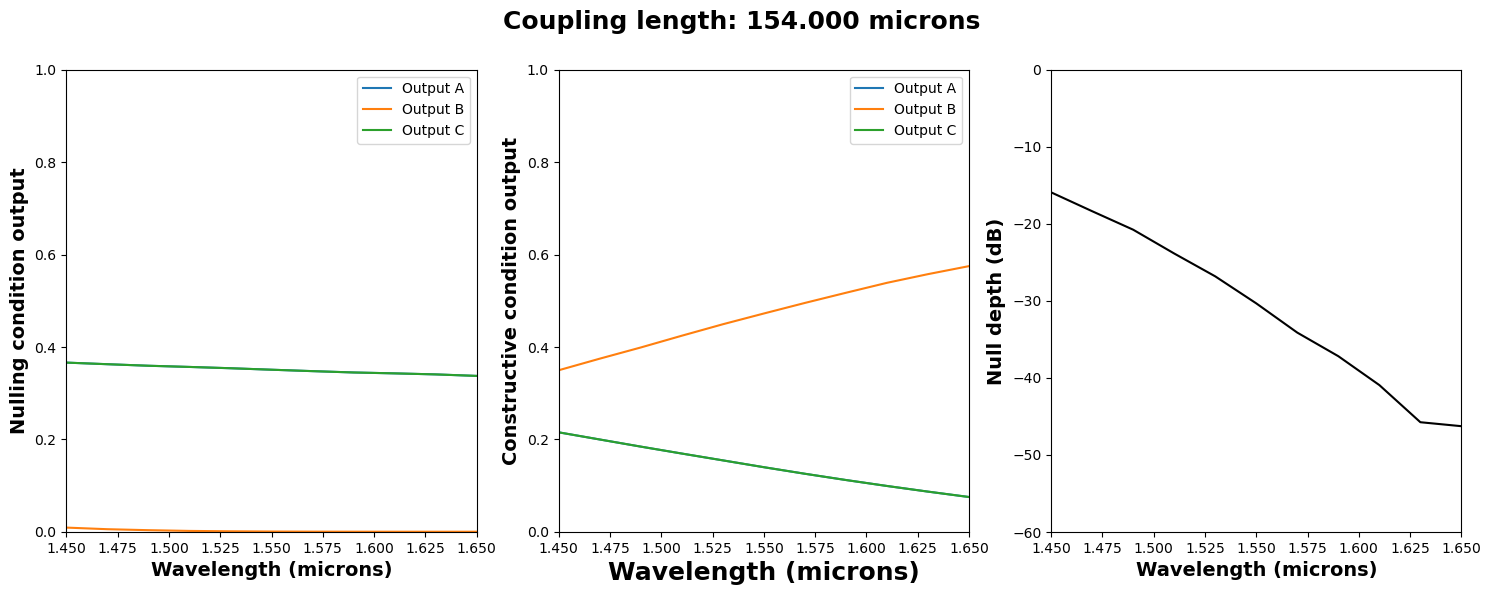

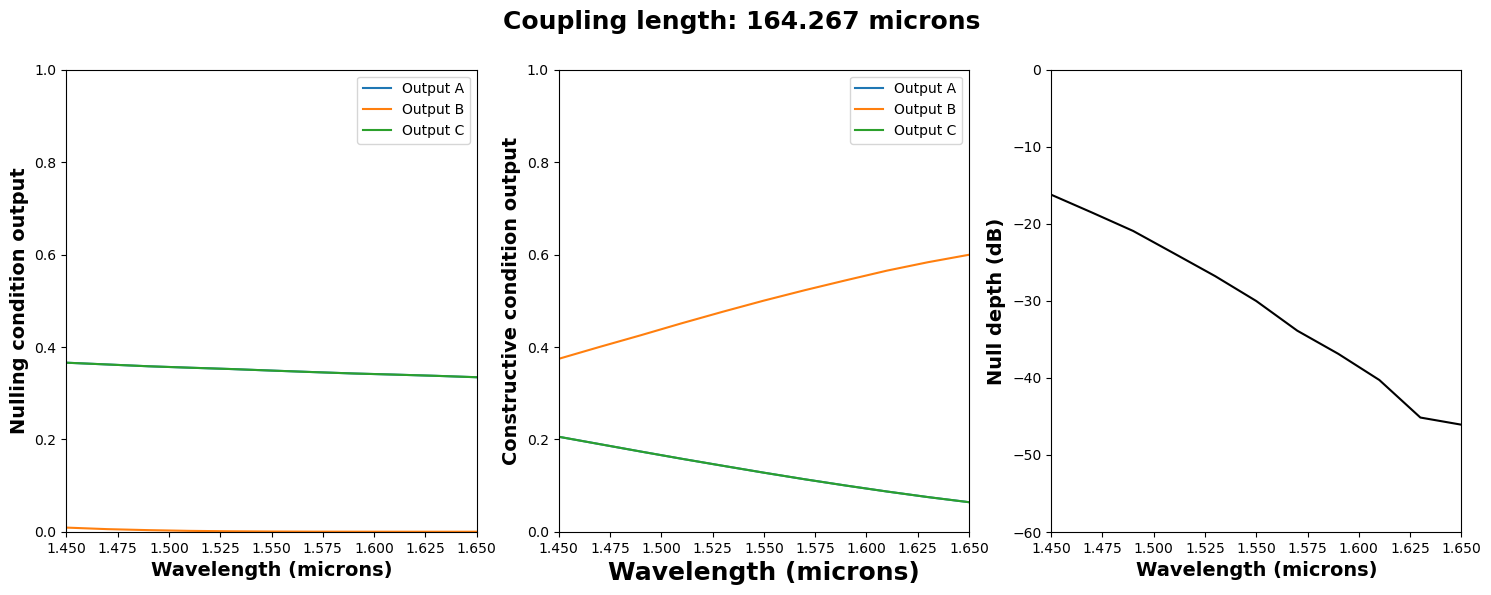

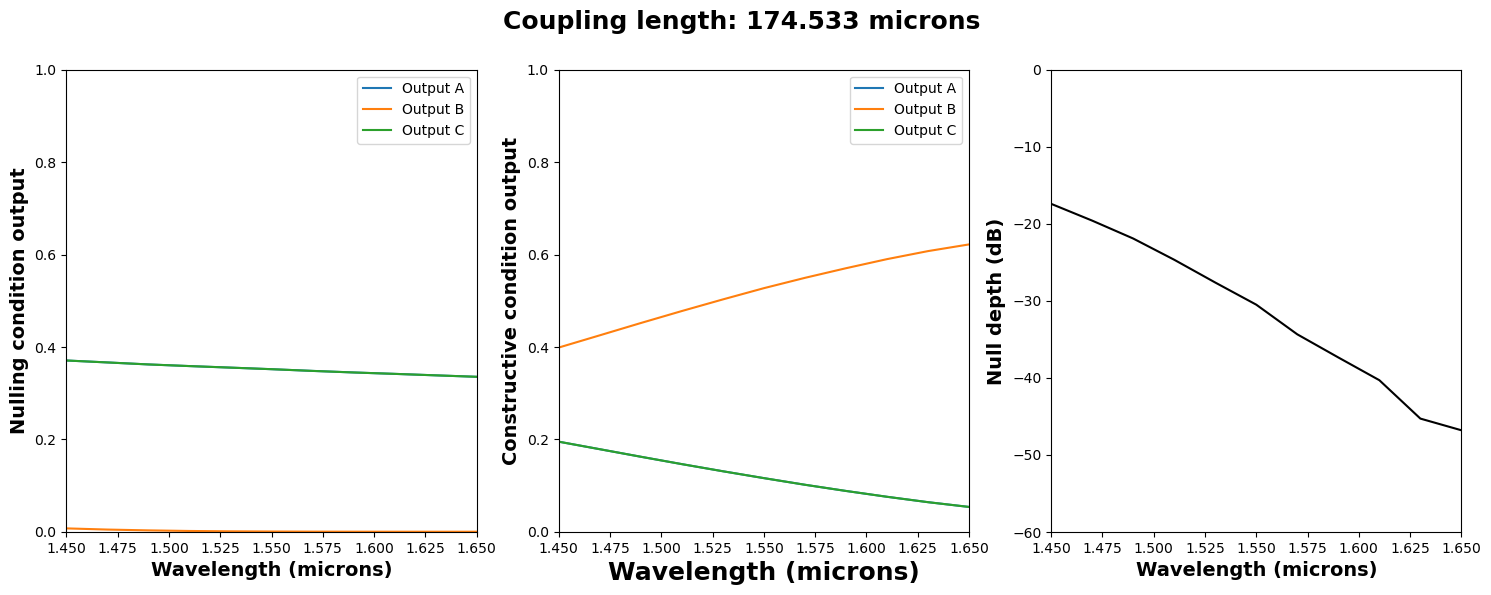

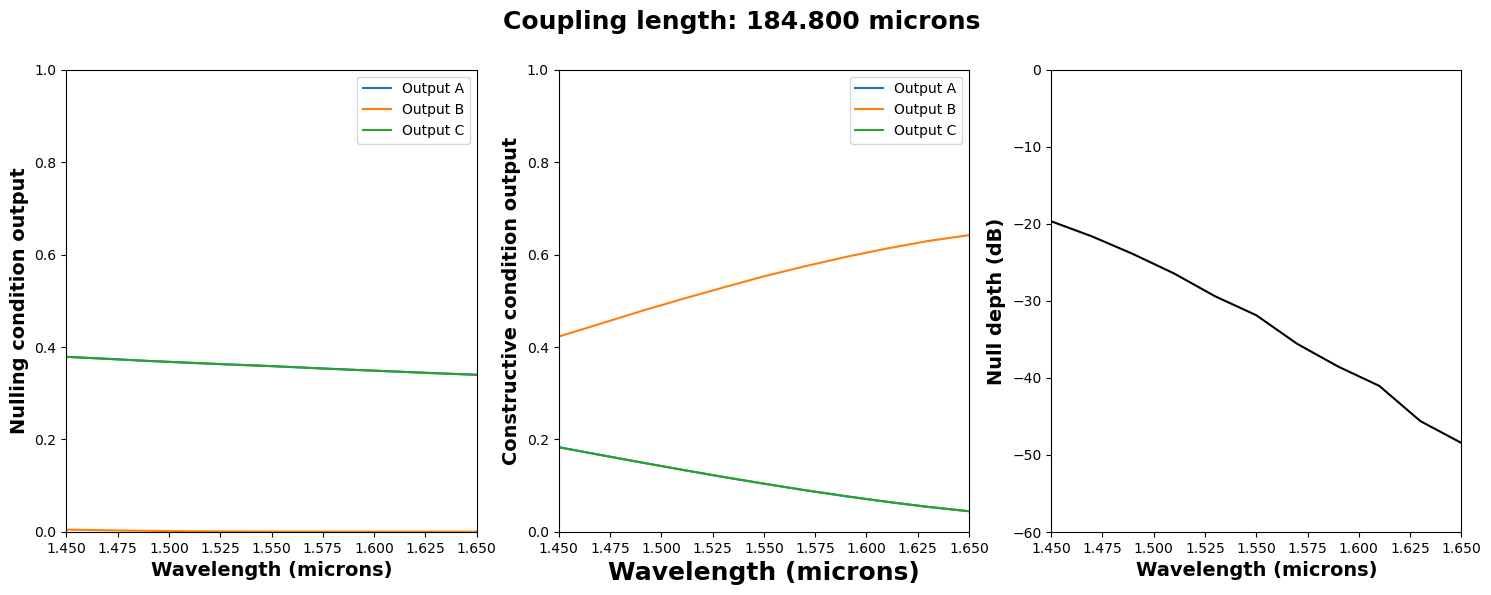

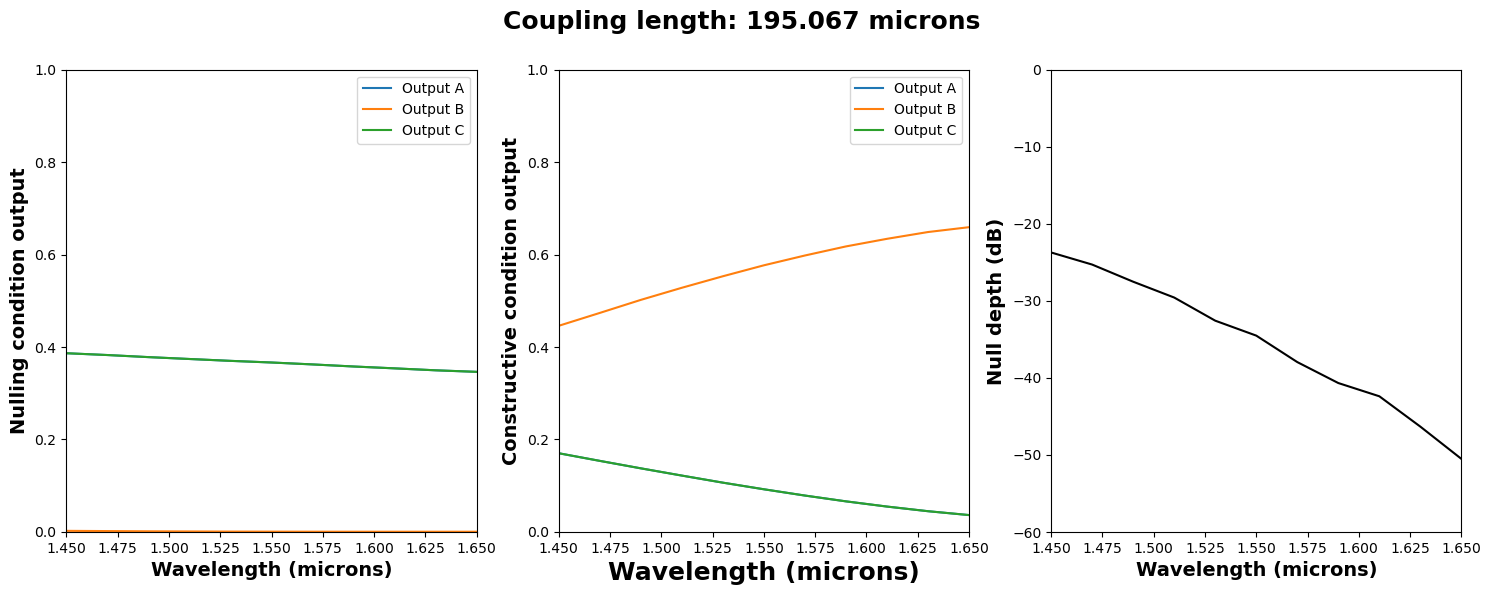

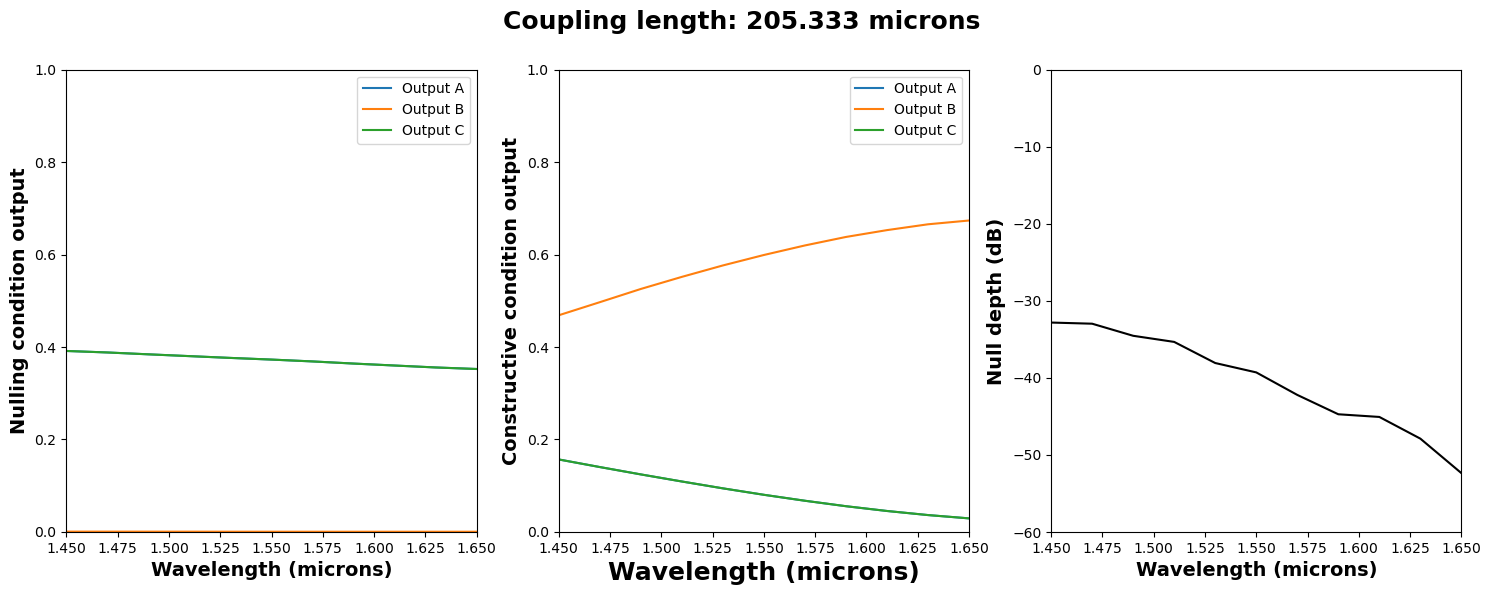

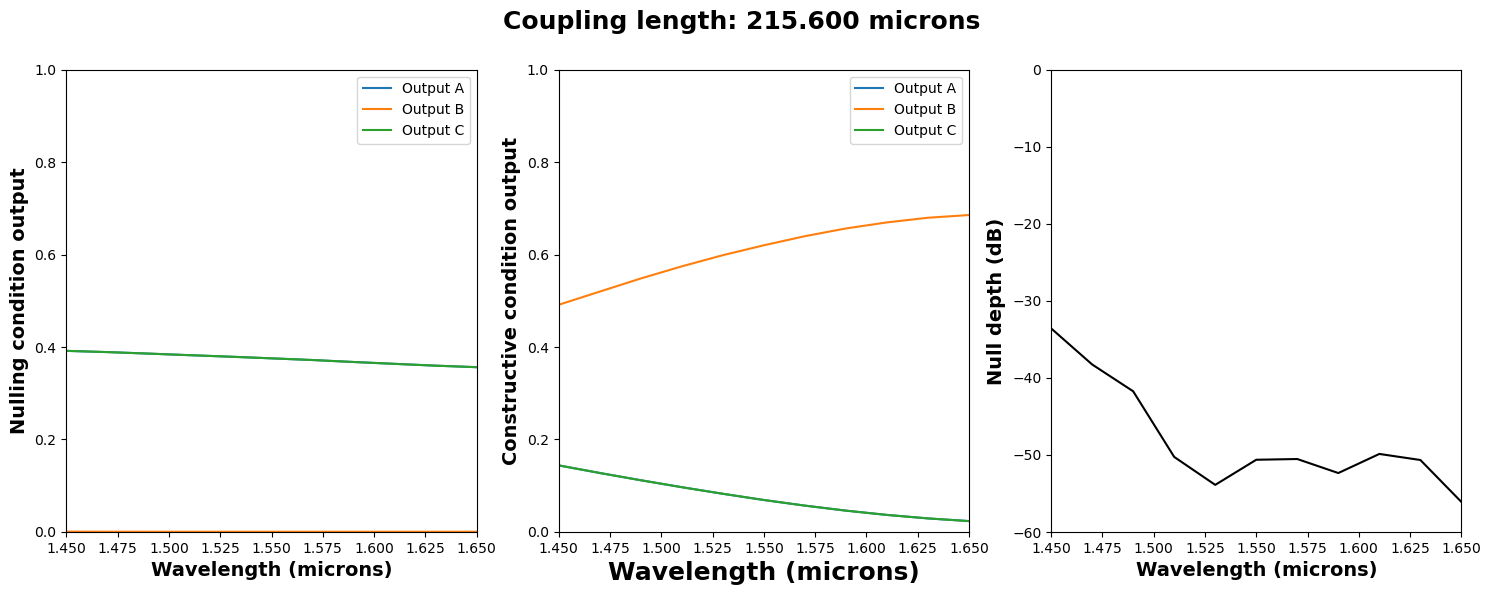

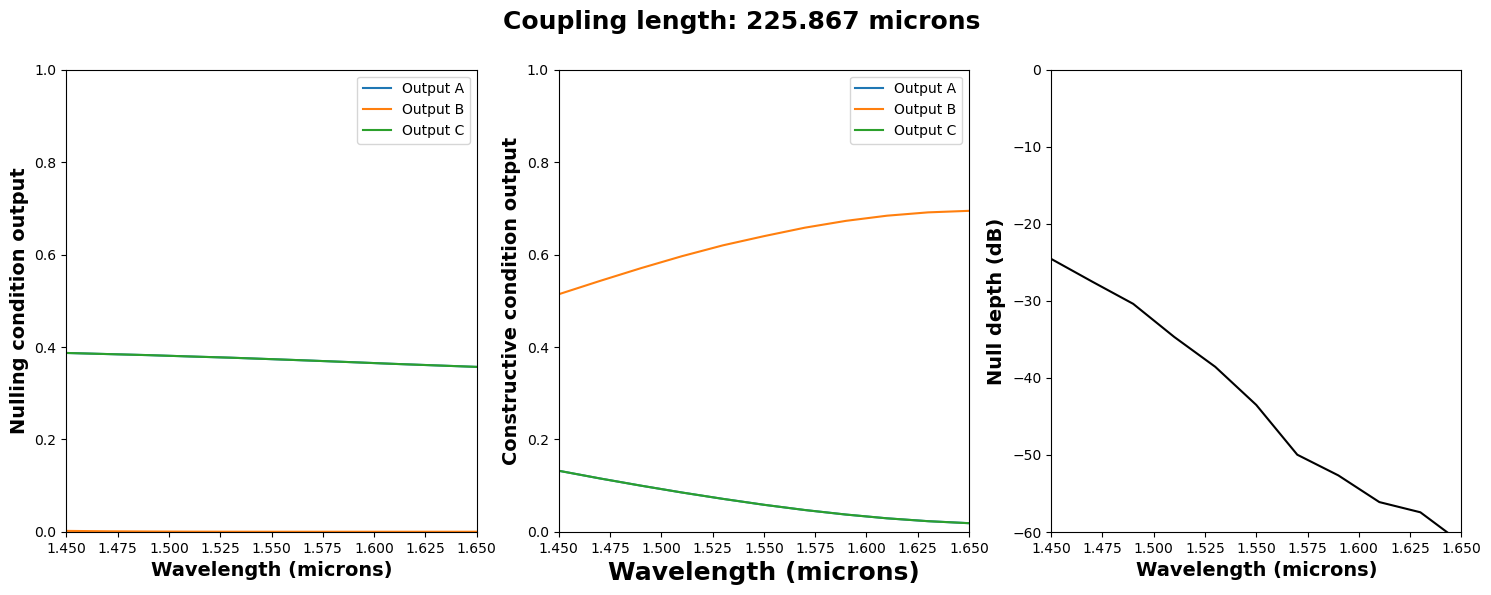

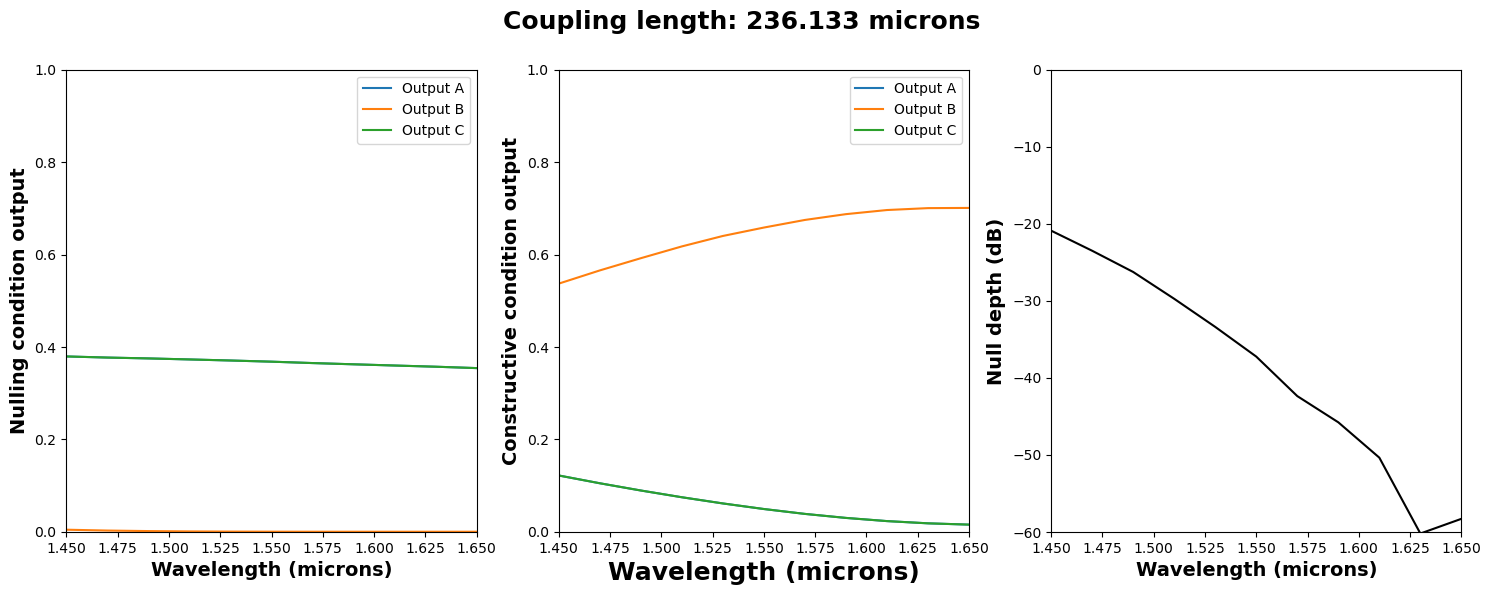

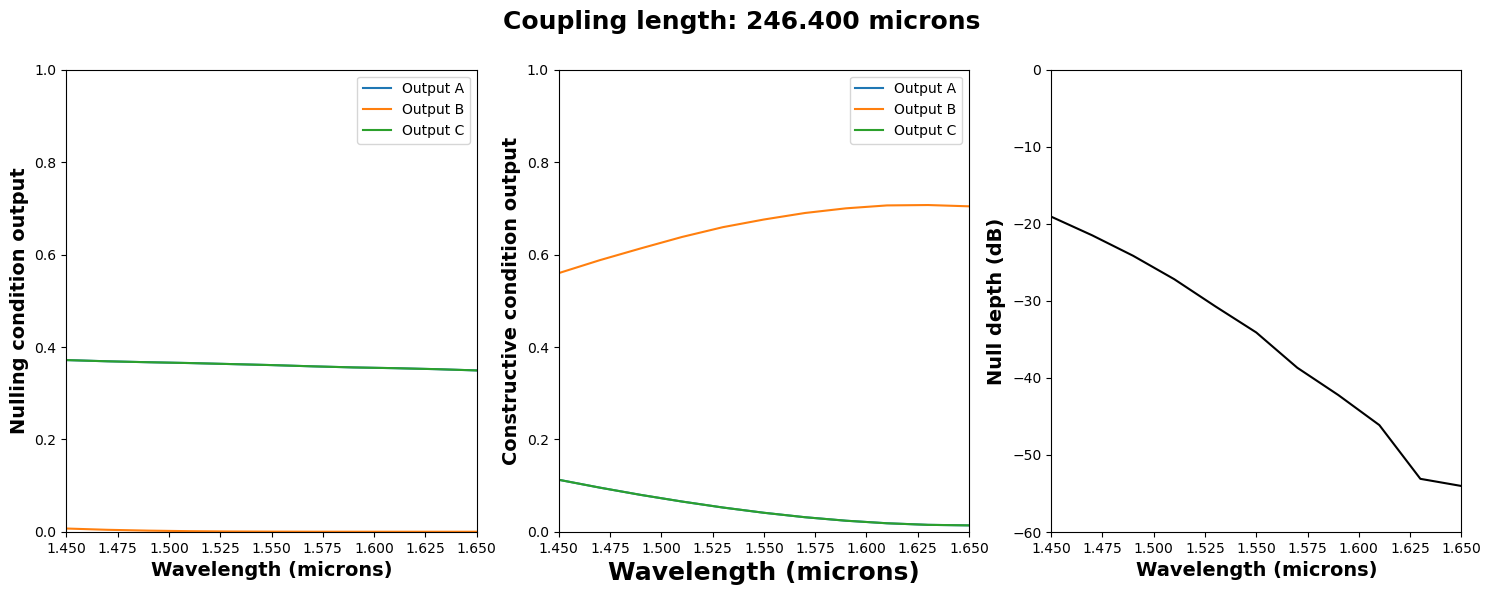

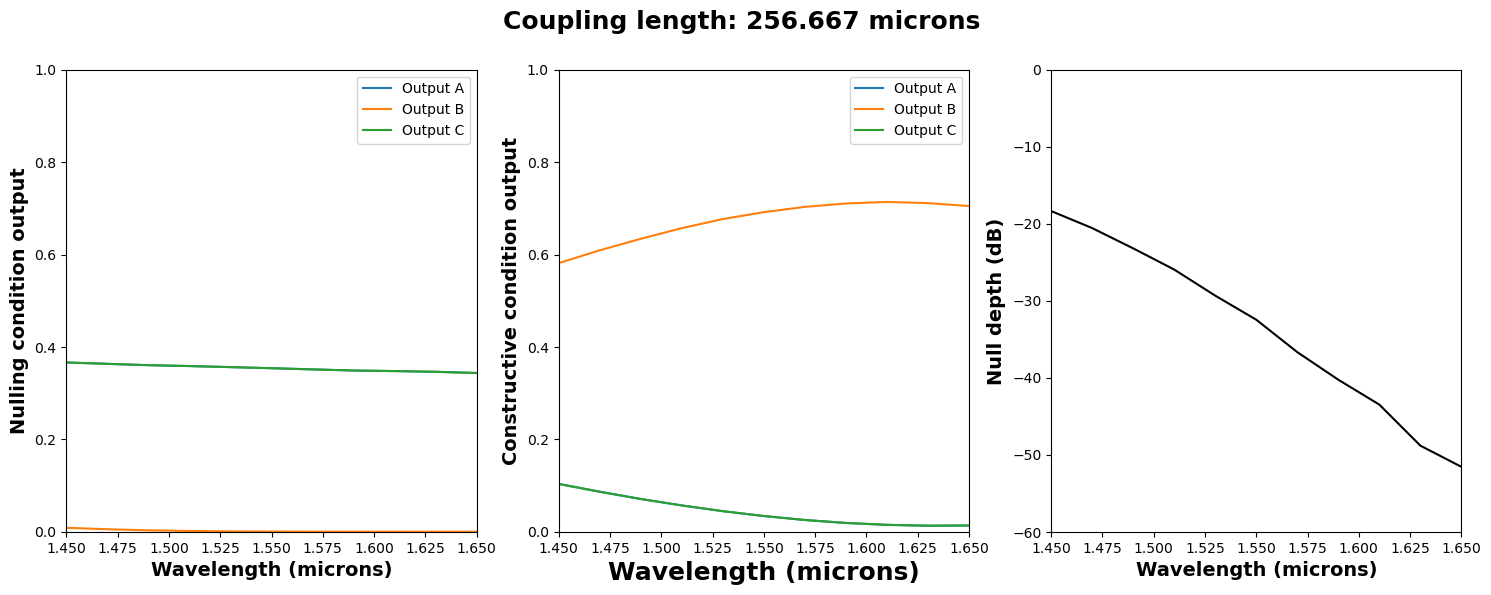

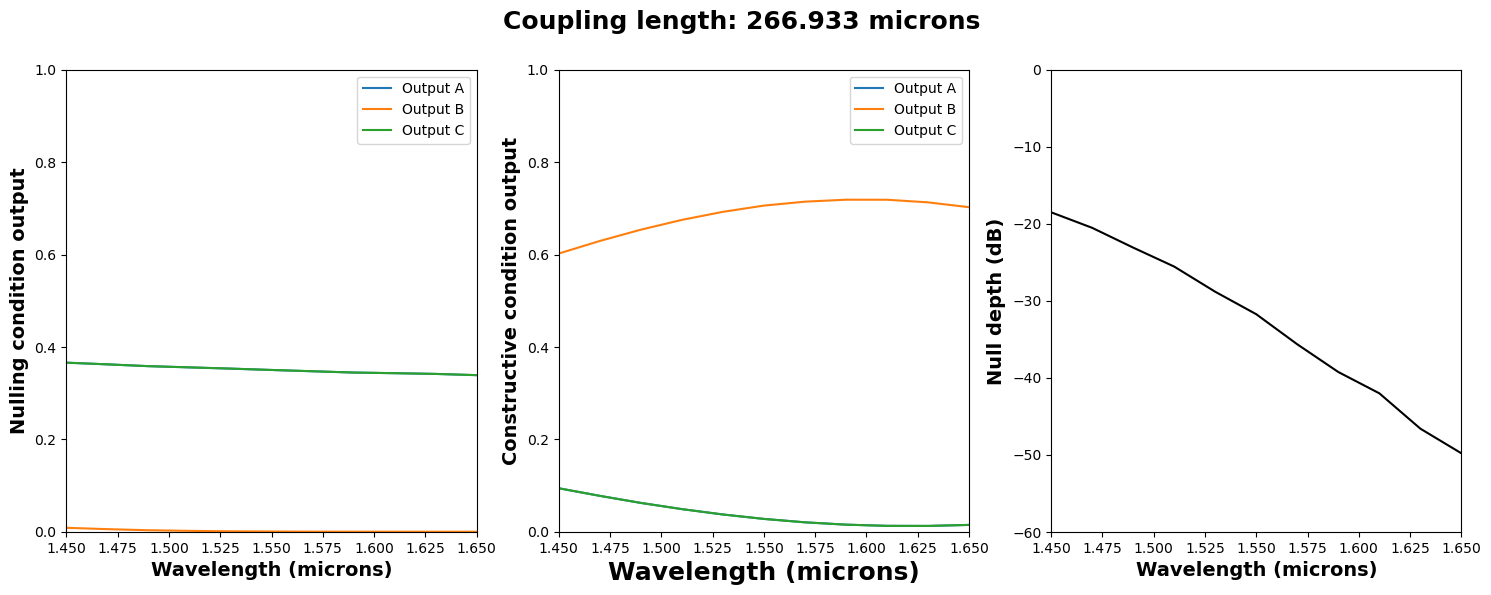

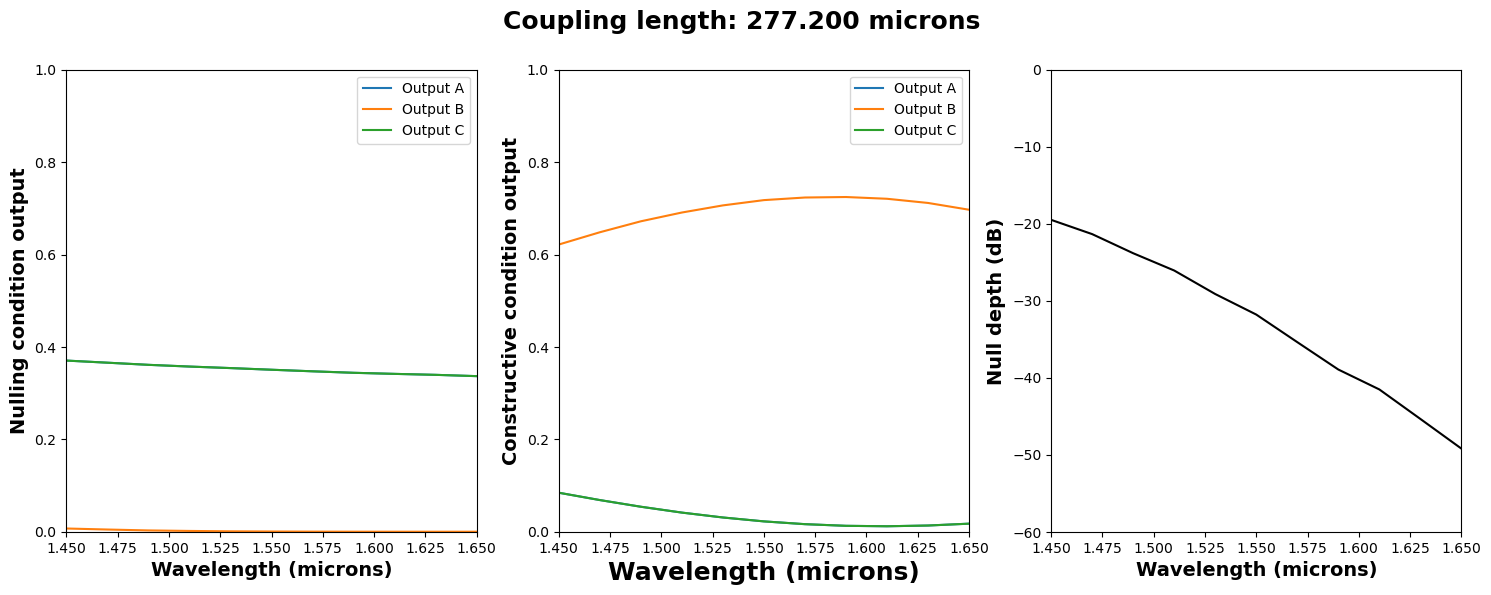

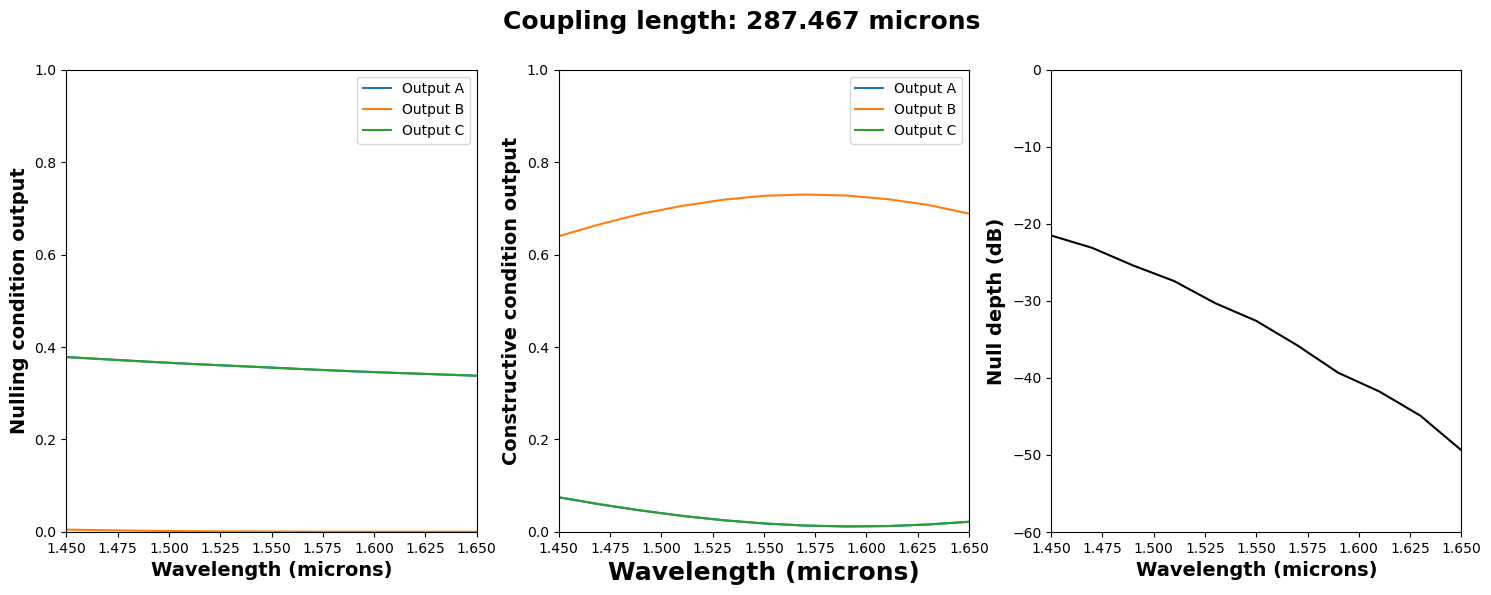

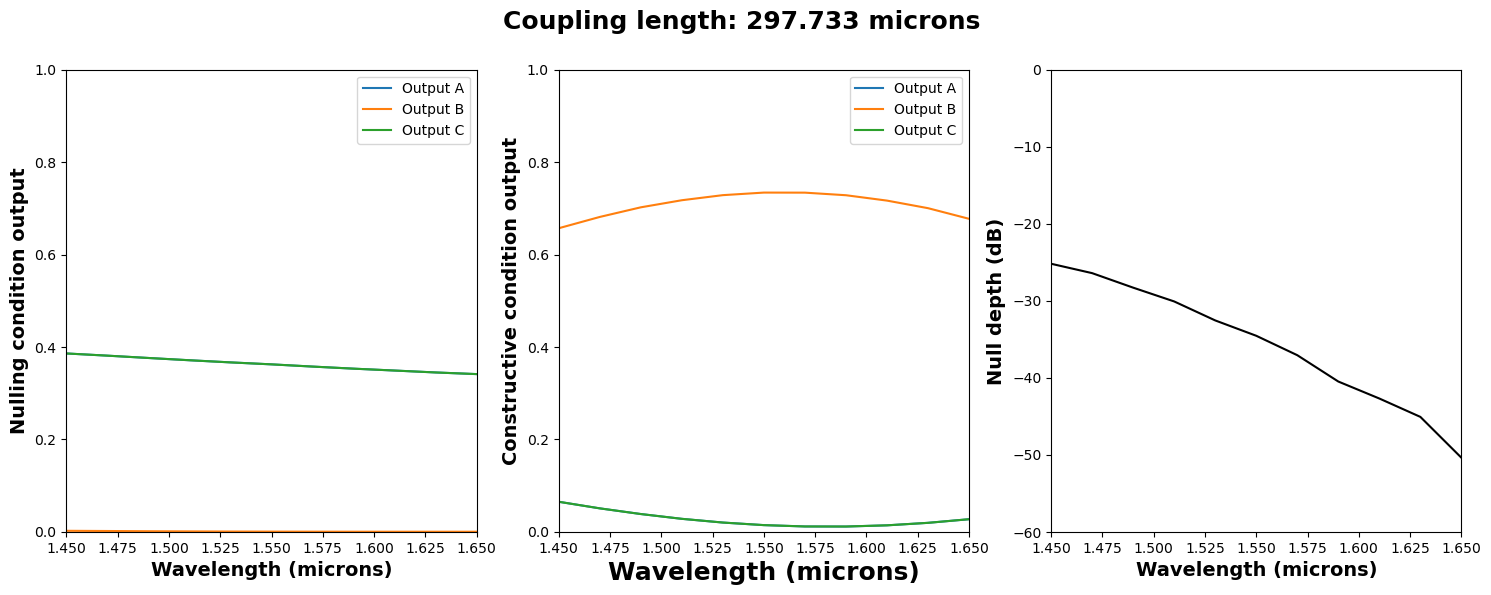

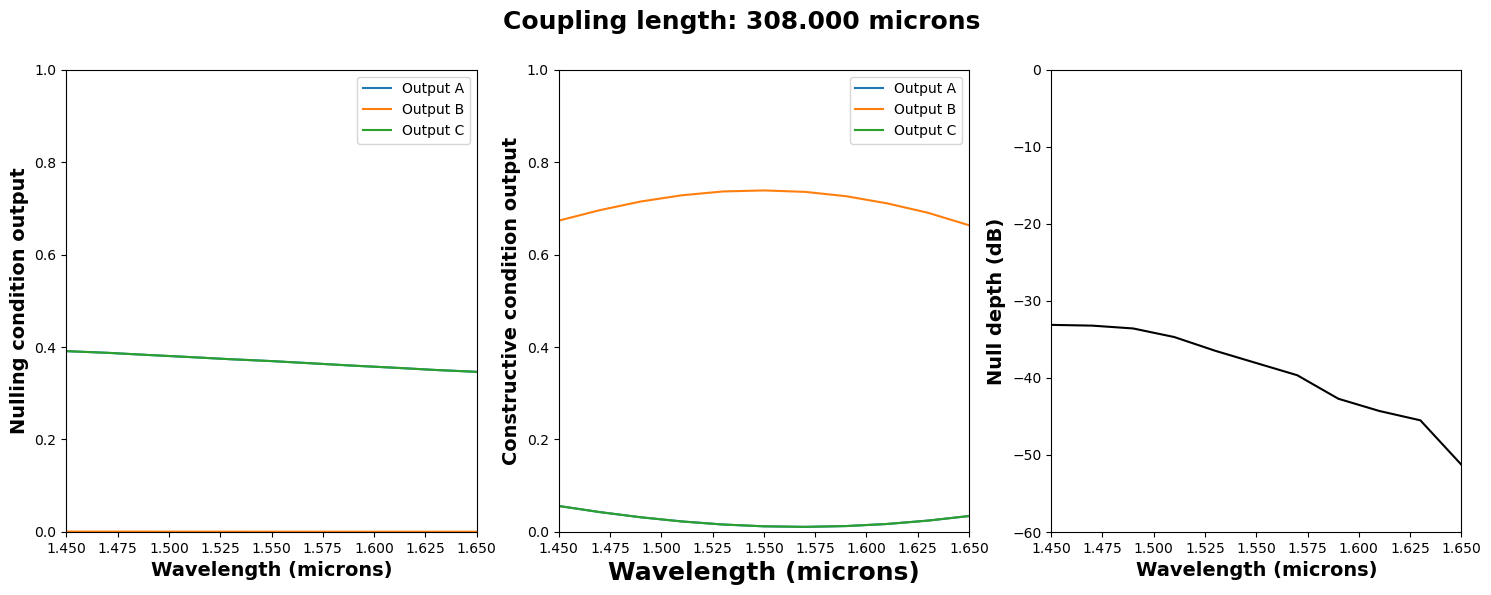

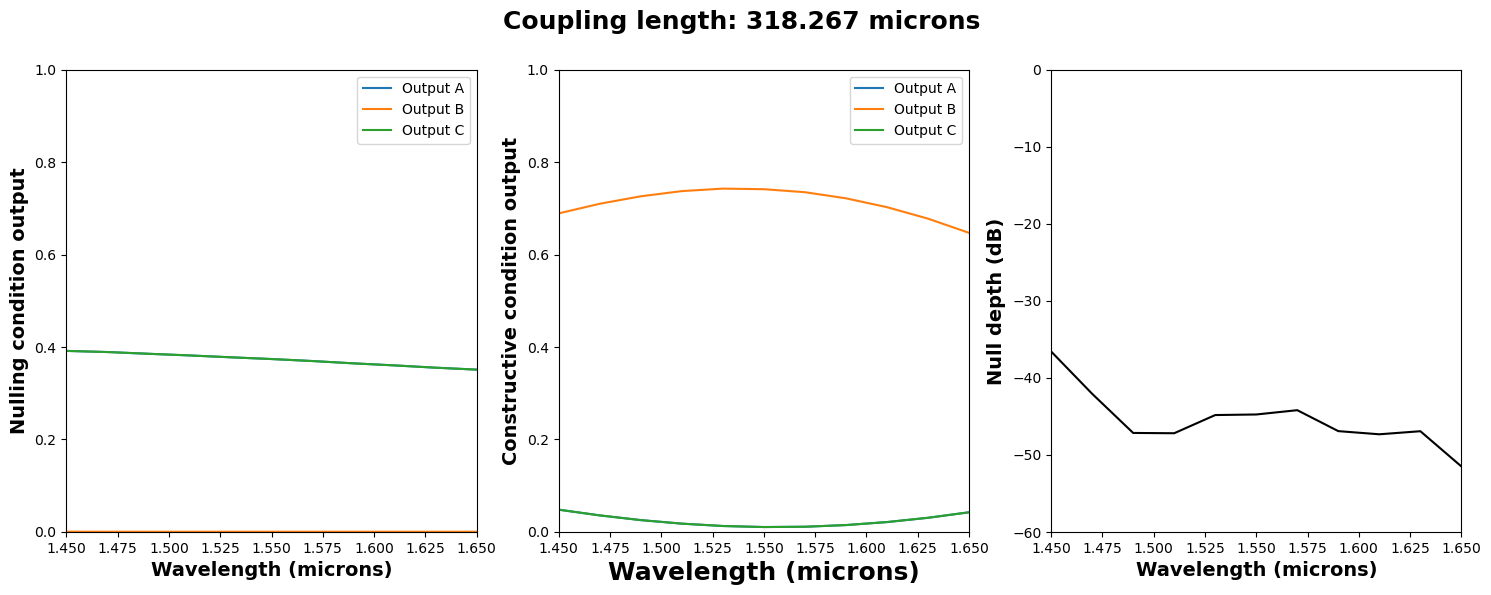

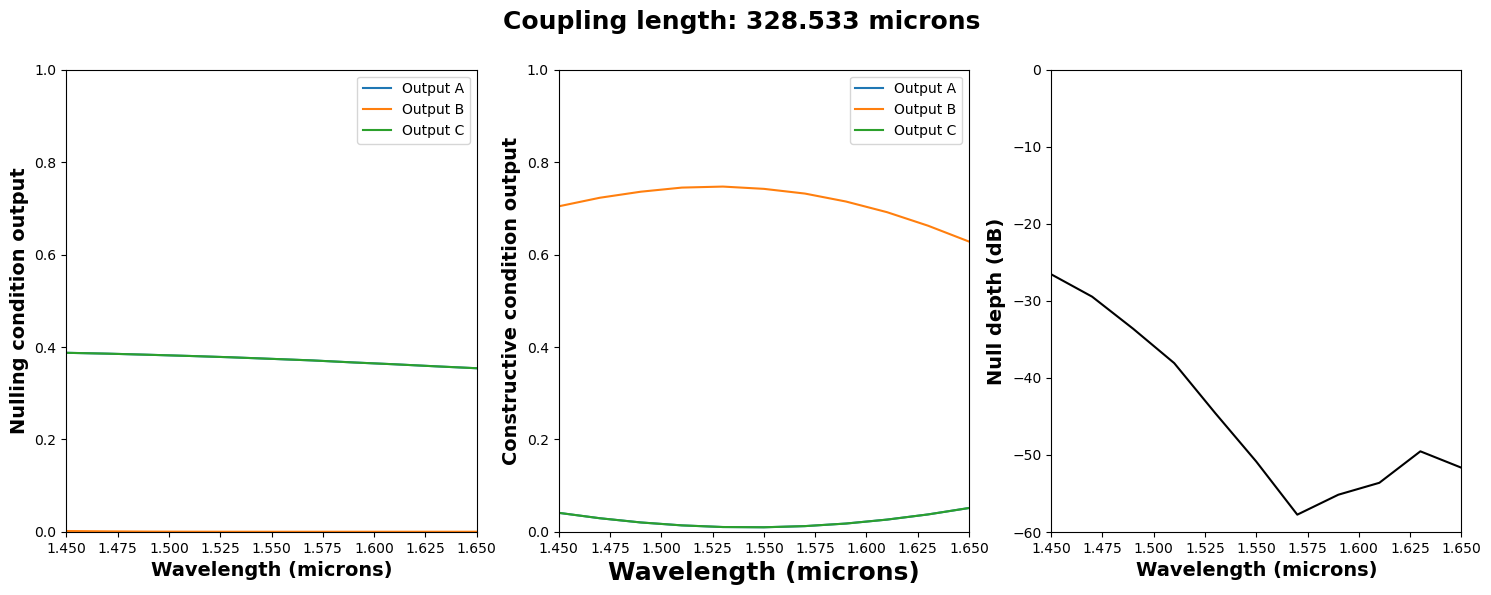

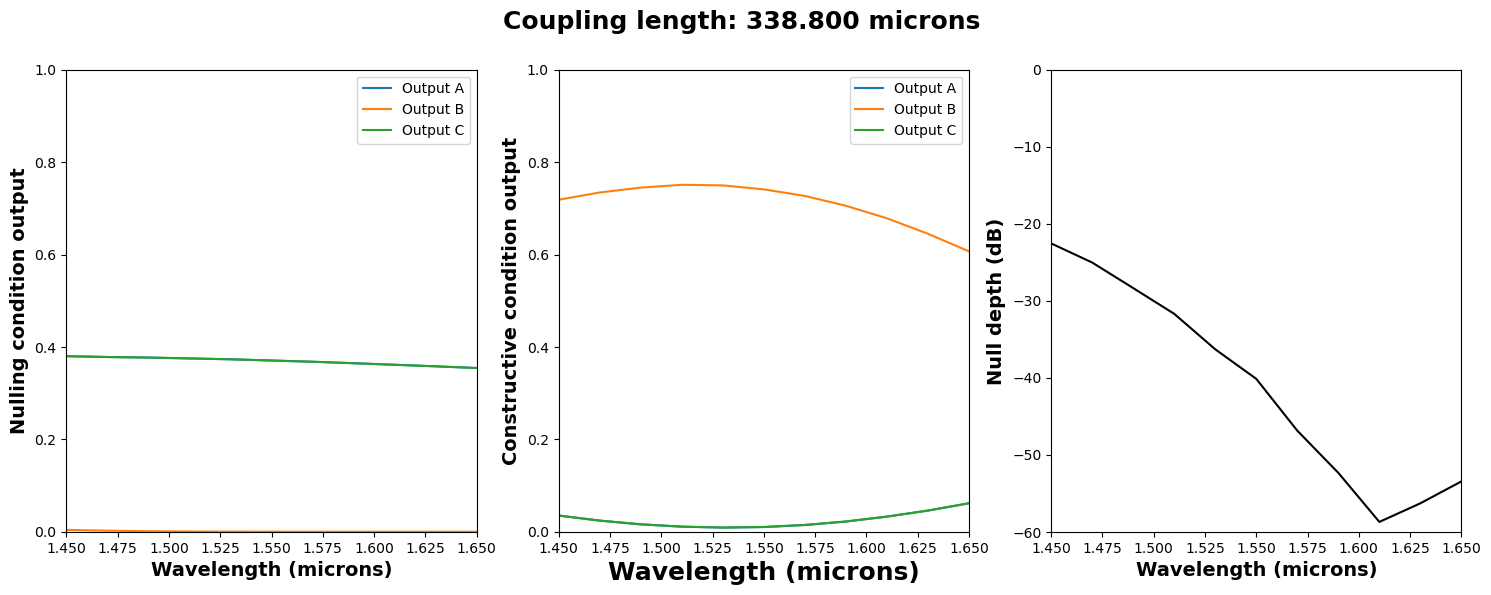

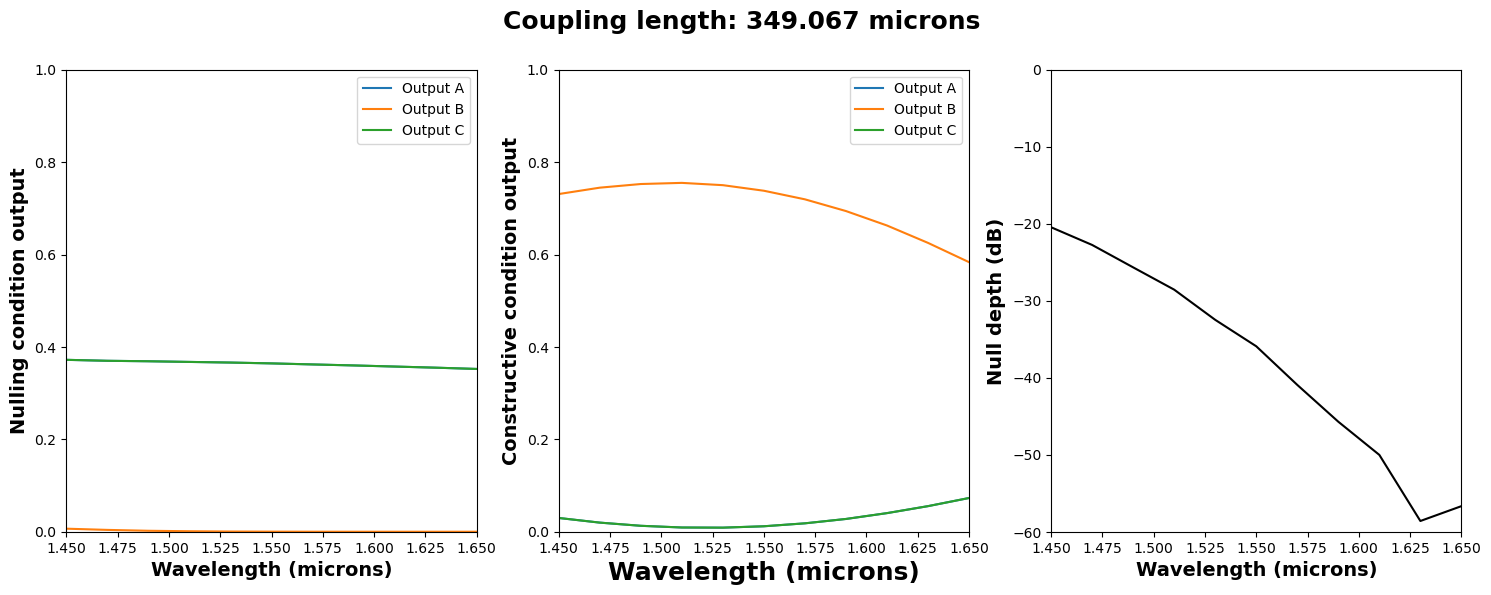

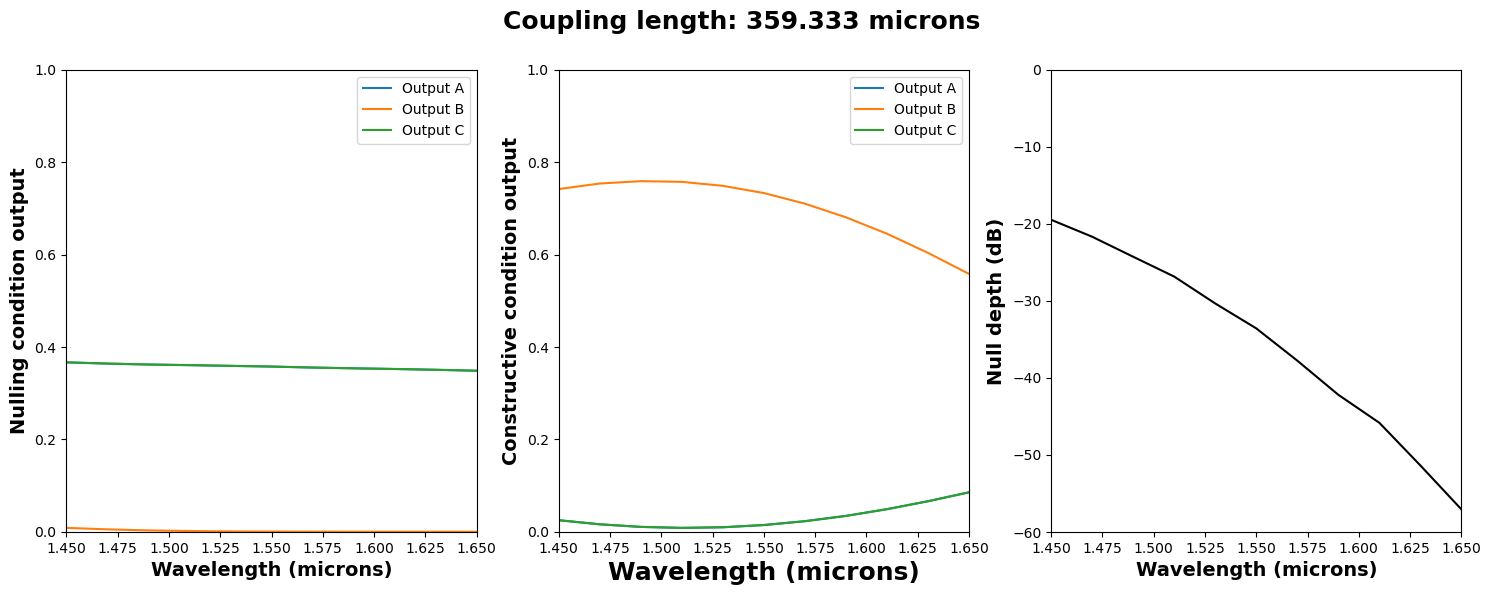

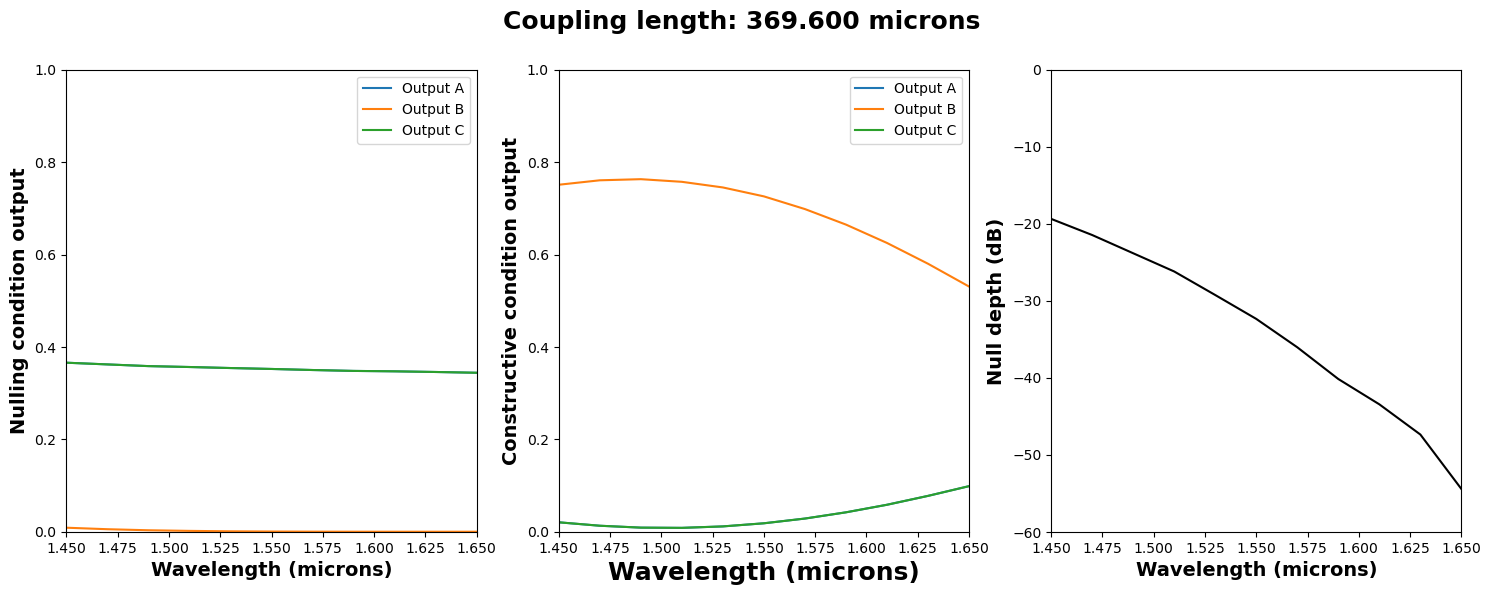

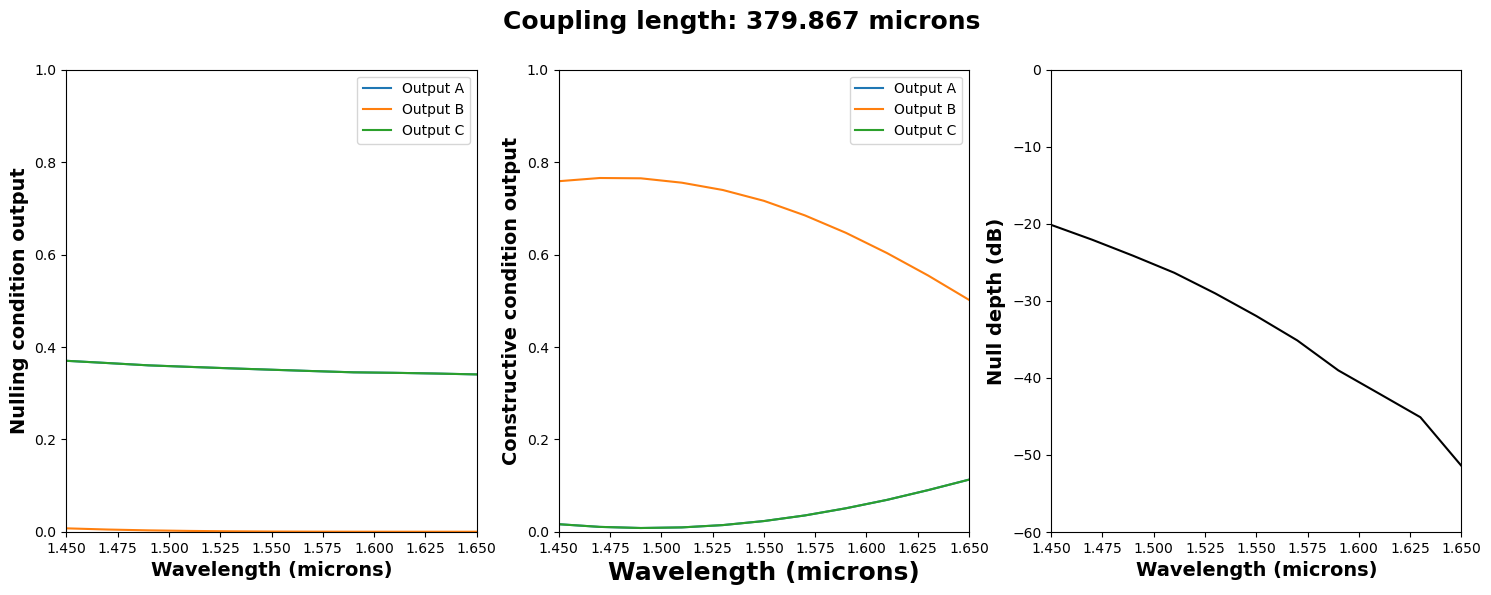

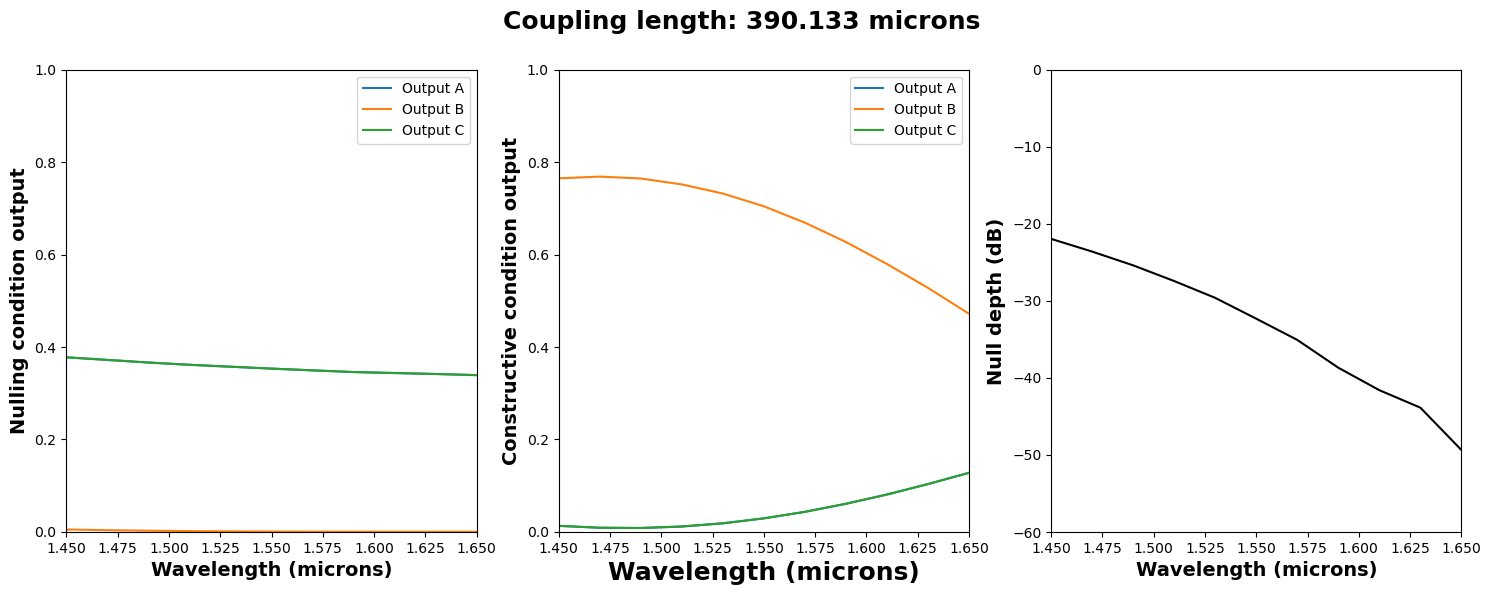

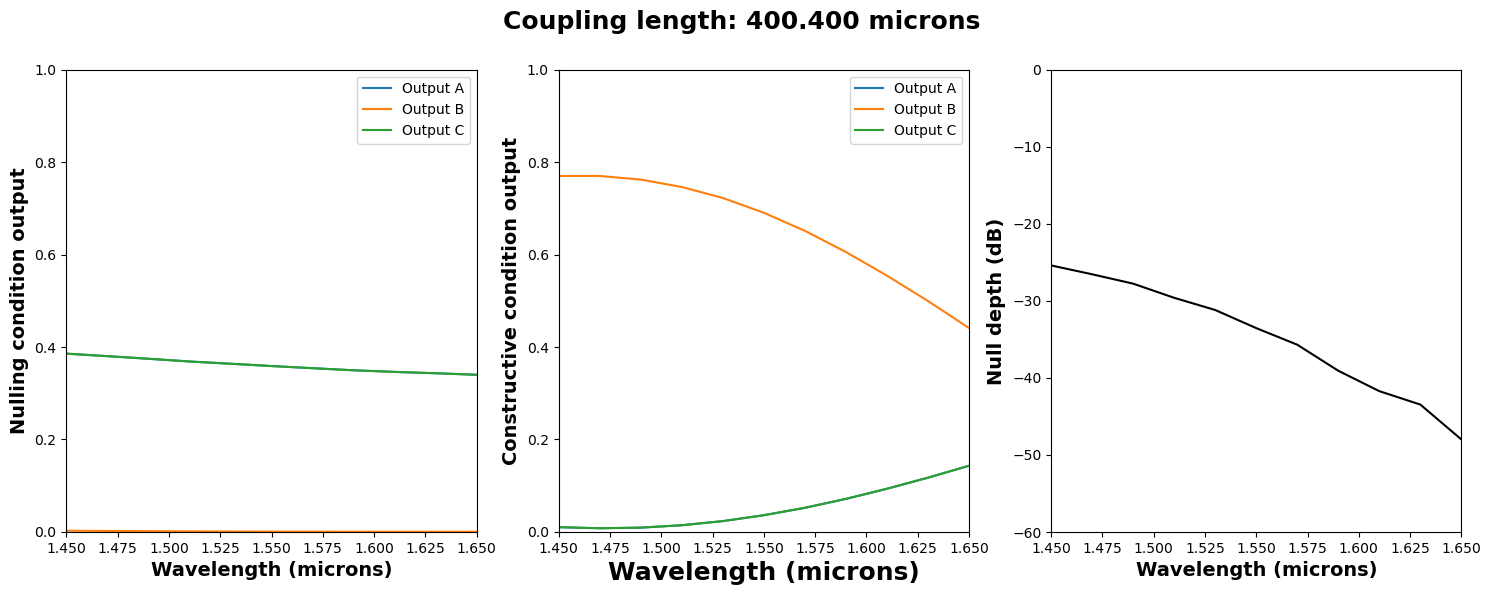

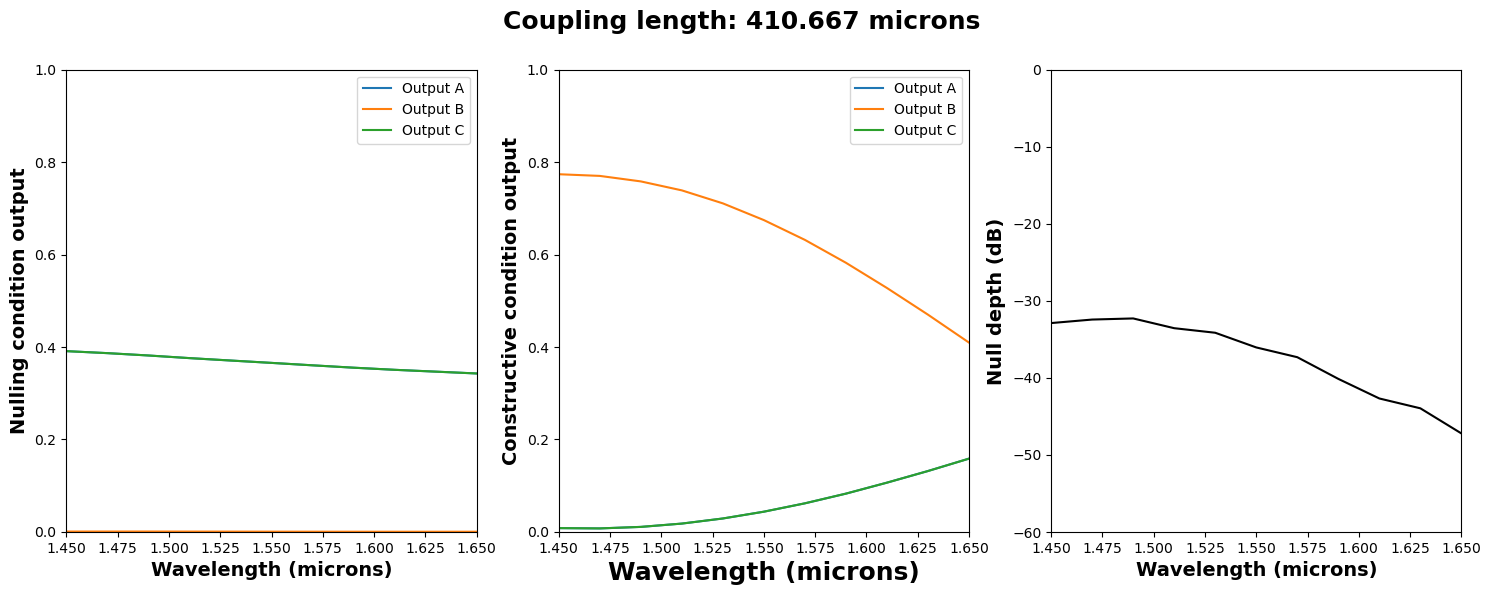

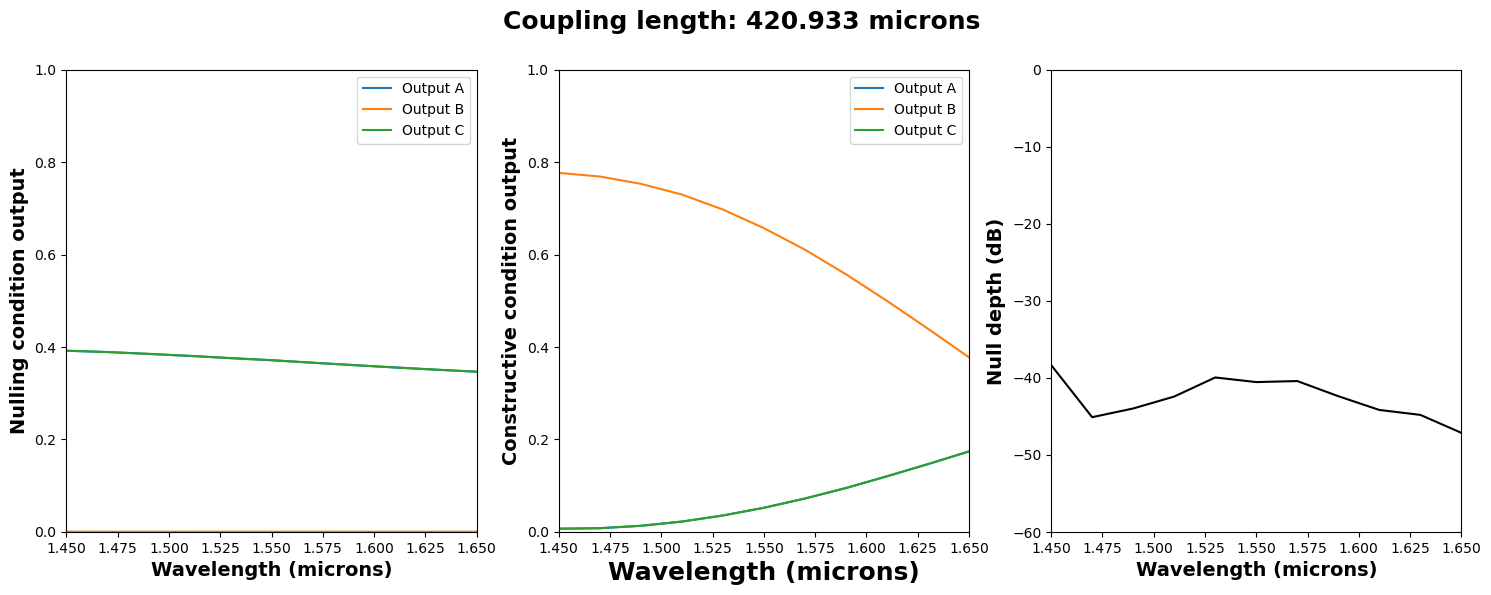

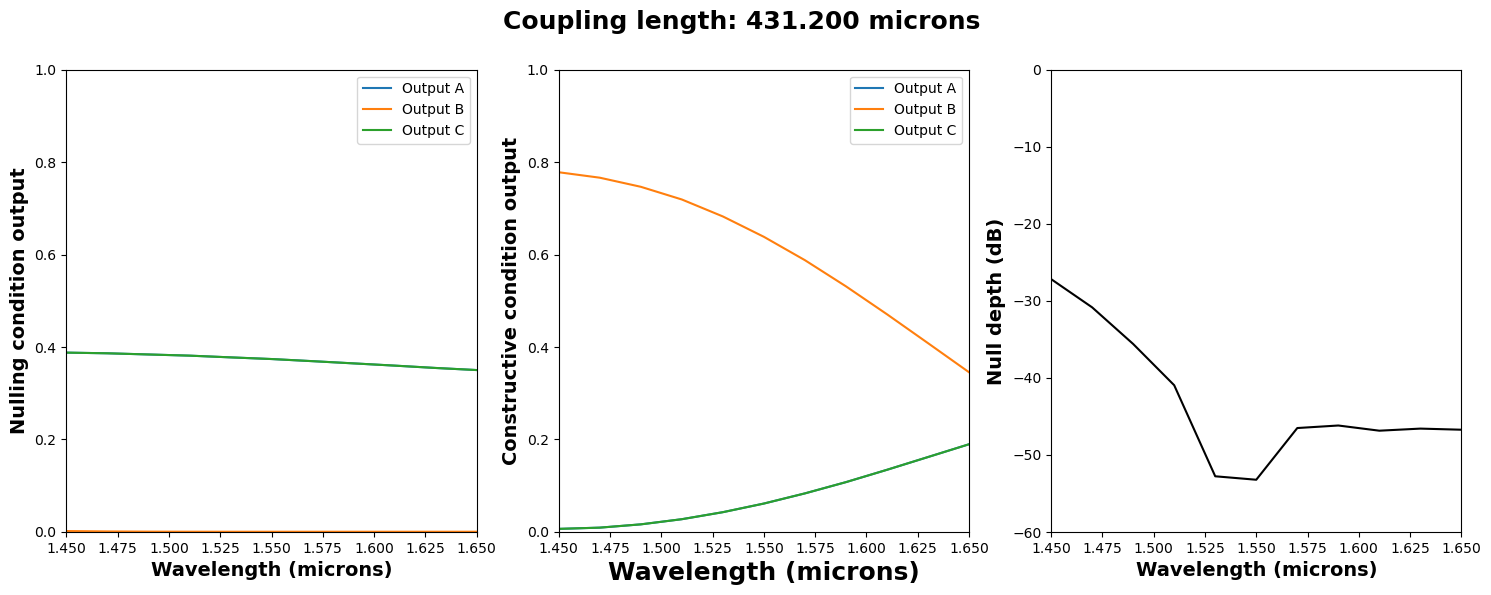

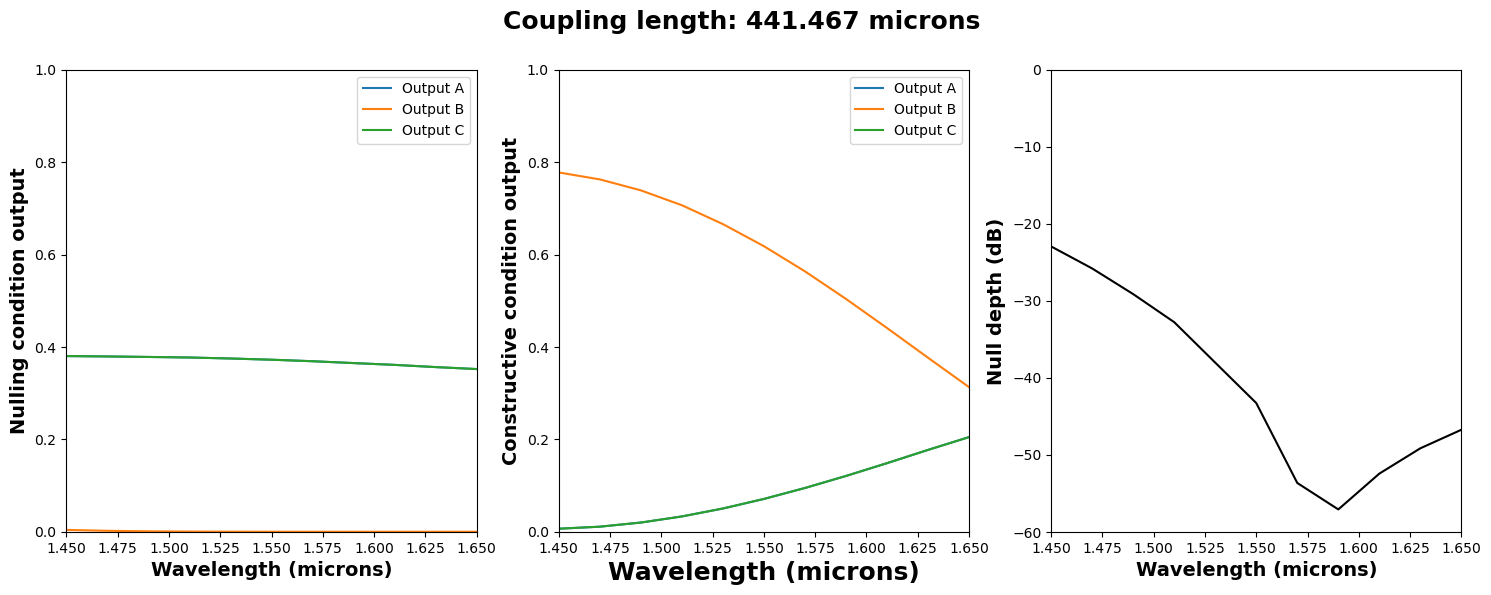

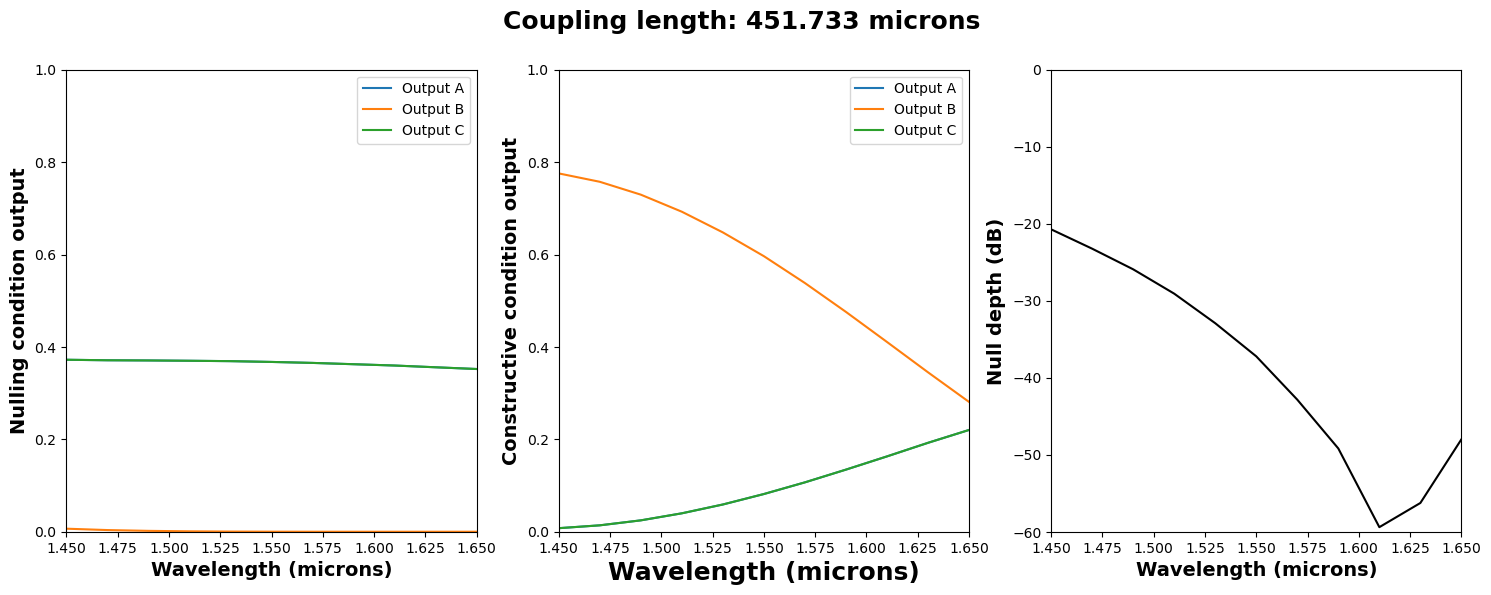

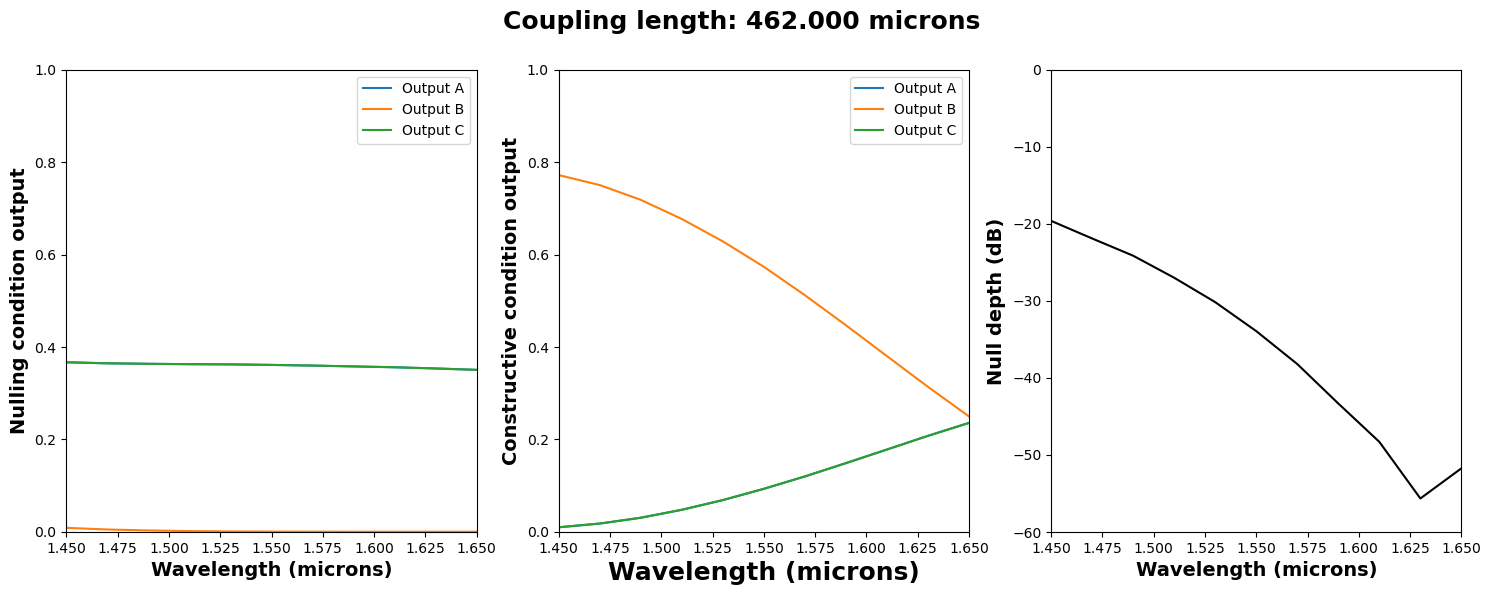

In [16]:
from matplotlib.animation import FuncAnimation, PillowWriter

for i, coupleLength in enumerate(coupleLength_arr):
    fig, ax = plt.subplots(1, 3, figsize=(18,6))
    
    ax[0].plot(wav_arr, outputs_null[i][:,0], label='Output A')
    ax[0].plot(wav_arr, outputs_null[i][:,1], label='Output B')
    ax[0].plot(wav_arr, outputs_null[i][:,2], label='Output C')
    ax[0].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
    ax[0].set_ylabel('Nulling condition output', fontsize=14, fontweight='bold')
    ax[0].set_xlim(min(wav_arr), max(wav_arr))
    ax[0].set_ylim(0, 1)
    ax[0].legend()

    ax[1].plot(wav_arr, outputs_max[i][:,0], label='Output A')
    ax[1].plot(wav_arr, outputs_max[i][:,1], label='Output B')
    ax[1].plot(wav_arr, outputs_max[i][:,2], label='Output C')
    ax[1].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
    ax[1].set_ylabel('Constructive condition output', fontsize=14, fontweight='bold')
    ax[1].set_xlim(min(wav_arr), max(wav_arr))
    ax[1].set_ylim(0, 1)
    ax[1].legend()
    
    ax[2].plot(wav_arr, 10*np.log10(outputs_null[i][:,1]/outputs_max[i][:,1]), 'k')
    ax[2].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
    ax[2].set_ylabel('Null depth (dB)', fontsize=14, fontweight='bold')
    ax[2].set_xlim(min(wav_arr), max(wav_arr))
    ax[2].set_ylim(-60, 0)

    fig.suptitle(f'Coupling length: {coupleLength:.3f} microns', fontsize=18, fontweight='bold')
    plt.show

Three-beam nulling

In [51]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename = "Tricoupler_FiberThreeInput"

filename_root = filename
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
filename = f"{filename}.ind"

wav_arr = np.linspace(1.45, 1.65, 11)
# wav_arr = [1.55]
coupleLength_arr = np.linspace(80, 180, 25)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for coupleLength in tqdm(coupleLength_arr, desc=f"Coupling length loop (Wavelength: {wav} microns)", position=1, leave=False):
        # Read in circuit, set probe wavelength
        phase = 180
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)
    
        # Read in circuit, set probe wavelength
        phase = 0
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)#*np.exp(-4))
        c.write(working_dir+filename)
        wav_str, phase_str, coupleLength_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p"), f"{coupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}",
                   "wait=0"] 
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_CouplingLength.npy", coupleLength_arr)

Wavelength loop: 0it [00:00, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   0%|                                          | 0/25 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.45 microns):   4%|█▎                                | 1/25 [00:18<07:18, 18.26s/it]
Coupling length loop (Wavelength: 1.45 microns):   8%|██▋                               | 2/25 [00:32<06:03, 15.82s/it]
Coupling length loop (Wavelength: 1.45 microns): 100%|█████████████████████████████████| 25/25 [06:32<00:00, 16.70s/it]
Wavelength loop: 1it [06:32, 392.30s/it]                                                                               
Coupling length loop (Wavelength: 1.47 microns):   0%|                                          | 0/25 [00:00<?, ?it/s]
Coupling length loop (Wavelength: 1.47 microns):   4%|█▎                                | 1/25 [00:14<05:55, 14.80s/it]
Coupling length loop (Wavelength: 1.47 microns):   8%|██▋                               | 2/25 [00:29<05:37, 14.69s/it]
Coup

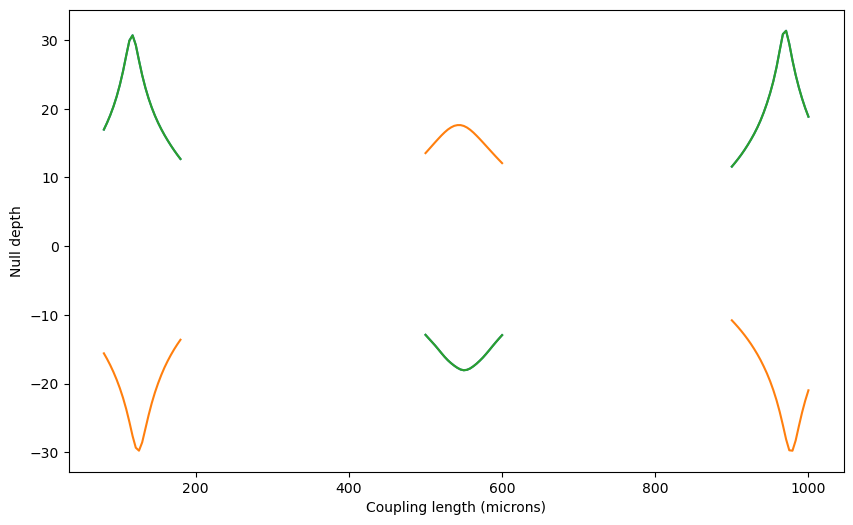

In [48]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberThreeInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_coupleLength"
# wav_arr = np.load(f"{save_dir}/{filename_root}_Wav.npy")
# coupleLength_arr = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")

coupleLength_all = [np.linspace(80, 180, 25), np.linspace(500, 600, 25), np.linspace(900, 1000, 25)]
plt.figure(figsize=(10,6))
for coupleLength_arr in coupleLength_all:
    wav_arr = [1.55]
    # coupleLength_arr = np.linspace(100, 200, 25)

    outputs_max, outputs_null = [], []
    for coupleLength in coupleLength_arr:
        coupleLength_str = f"{coupleLength:0.3f}".replace(".", "p")
        output_max, output_null = [], []
        for wav in wav_arr[:1]:
            phase = 0
            wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
            filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
            sim = np.genfromtxt(filename, skip_header=5)
            output_max.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])
    
            phase = 180
            wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
            filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
            sim = np.genfromtxt(filename, skip_header=5)
            output_null.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])
        outputs_max.append(output_max)
        outputs_null.append(output_null)
    outputs_max, outputs_null = np.array(outputs_max), np.array(outputs_null)
    
    for i in range(3):
        plt.plot(coupleLength_arr, 10*np.log10(outputs_null[:,0,i]/outputs_max[:,0,i]), color=f'C{i}')
plt.xlabel('Coupling length (microns)')
plt.ylabel('Null depth')
plt.show()

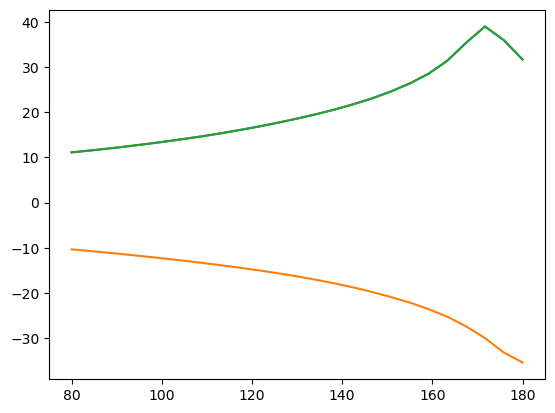

In [59]:
# wav_arr = [1.55]
# coupleLength_arr = np.linspace(500, 600, 25)
wav_arr = np.load(f"{save_dir}/{filename_root}_Wav.npy")
coupleLength_arr = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")

outputs_max, outputs_null = [], []
for coupleLength in coupleLength_arr:
    coupleLength_str = f"{coupleLength:0.3f}".replace(".", "p")
    output_max, output_null = [], []
    for wav in wav_arr:
        phase = 0
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_max.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])

        phase = 180
        wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
        filename = f'{save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}_CoupleLength{coupleLength_str}.mon'
        sim = np.genfromtxt(filename, skip_header=5)
        output_null.append([sim[-1, 1], sim[-1, 2], sim[-1, 3]])
    outputs_max.append(output_max)
    outputs_null.append(output_null)
outputs_max, outputs_null = np.array(outputs_max), np.array(outputs_null)

for i in range(3):
    plt.plot(coupleLength_arr, 10*np.log10(outputs_null[:,0,i]/outputs_max[:,0,i]))

In [60]:
from matplotlib.animation import FuncAnimation, PillowWriter
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Create persistent line objects
lines_null = [ax[0].plot([], [], label=f'Output {c}')[0] for c in ['A', 'B', 'C']]
lines_max  = [ax[1].plot([], [], label=f'Output {c}')[0] for c in ['A', 'B', 'C']]
line_db    = ax[2].plot([], [], 'k')[0]

# Static axis formatting
ax[0].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Nulling condition output', fontsize=14, fontweight='bold')
ax[0].set_xlim(min(wav_arr), max(wav_arr))
ax[0].set_ylim(0, 1)
ax[0].legend()

ax[1].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Constructive condition output', fontsize=14, fontweight='bold')
ax[1].set_xlim(min(wav_arr), max(wav_arr))
ax[1].set_ylim(0, 1)
ax[1].legend()

ax[2].set_xlabel('Wavelength (microns)', fontsize=14, fontweight='bold')
ax[2].set_ylabel('Null depth (dB)', fontsize=14, fontweight='bold')
ax[2].set_xlim(min(wav_arr), max(wav_arr))
ax[2].set_ylim(-60, 0)

def update(i):
    # Null outputs
    for j in range(3):
        lines_null[j].set_data(wav_arr, outputs_null[i][:, j])

    # Constructive outputs
    for j in range(3):
        lines_max[j].set_data(wav_arr, outputs_max[i][:, j])

    # Null depth
    db = 10 * np.log10(outputs_null[i][:,1] / outputs_max[i][:,1])
    line_db.set_data(wav_arr, db)

    fig.suptitle(
        f'Coupling length: {coupleLength_arr[i]:.3f} microns',
        fontsize=18,
        fontweight='bold'
    )

    return (*lines_null, *lines_max, line_db)

ani = FuncAnimation(
    fig,
    update,
    frames=len(coupleLength_arr),
    interval=200,   # ms per frame
    blit=False
)

ani.save('tricoupler_scan.gif', writer=PillowWriter(fps=2))

plt.close(fig)

### Cascaded tricoupler

In [62]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
# wav_str, phase_str = f"{wav:0.3f}".replace(".", "p"), f"{phase:0.3f}".replace(".", "p")
filename_root = f"Tricoupler_2Layer"
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
save_dir = working_dir+f"{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength_DecoupleLength_CoupleLengthTwo"
filename = f"{filename_root}.ind"

coupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)
decoupleLength_arr = np.linspace(0.5*308, 1.5*308, 31)
coupleLength2_arr = np.linspace(0.5*308, 1.5*308, 5)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for coupleLength in tqdm(coupleLength_arr, desc='Couple length loop', position=0, leave=False):
    for decoupleLength in tqdm(decoupleLength_arr, desc=f"Decouple length loop (Couple length: {coupleLength} microns)", position=1, leave=False): 
        for coupleLength2 in tqdm(coupleLength2_arr, desc=f"Couple length 2 loop (Couple length: {coupleLength} microns, Decouple length: {decoupleLength} microns)", position=1, leave=False): 
            # Read in circuit, set probe wavelength
            c = RSoftCircuit()
            c.read(working_dir+filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("PhaseShift", phase)
            c.set_symbol("TricouplerCoupleLength", coupleLength)
            c.set_symbol("TricouplerDecoupleLength", decoupleLength)
            c.set_symbol("TricouplerCoupleLength2", coupleLength2)
            c.write(working_dir+filename)
    
            couple_str = f"{coupleLength:0.3f}".replace(".", "p")
            decouple_str = f"{decoupleLength:0.3f}".replace(".", "p")
            couple2_str = f"{coupleLength2:0.3f}".replace(".", "p")
            command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength{couple_str}_DecoupleLength{decouple_str}_CoupleLengthTwo{couple2_str}", "wait=0"]
            
            # Run the command
            result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_CoupleLength.npy", coupleLength_arr)
np.save(f"{save_dir}/{filename_root}_DecoupleLength.npy", decoupleLength_arr)
np.save(f"{save_dir}/{filename_root}_CoupleLengthTwo.npy", coupleLength2_arr)

Couple length loop:   0%|                                                                       | 0/31 [00:00<?, ?it/s]
Decouple length loop (Couple length: 154.0 microns):   0%|                                      | 0/31 [00:00<?, ?it/s]
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):   0%|       | 0/5 [00:00<?, ?it/s]
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  20%|▏| 1/5 [00:09<00:36,  9.22s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  40%|▍| 2/5 [00:19<00:28,  9.65s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  60%|▌| 3/5 [00:29<00:19,  9.78s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns):  80%|▊| 4/5 [00:37<00:09,  9.23s/i
Couple length 2 loop (Couple length: 154.0 microns, Decouple length: 154.0 microns): 100%|█| 5/5 [00:46<00:00,  9.25s/i
                                        

In [23]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_Phase"
filename = f"{filename_root}.ind"

wav_arr = np.linspace(1.45, 1.65, 51)
phase_arr = np.linspace(0, 360, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for phase in tqdm(phase_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        # c.set_symbol("TricouplerCoupleLength", CoupleLength)
        # c.set_symbol("TricouplerDecoupleLength", DecoupleLength)
        c.write(working_dir+filename)

        wav_str = f"{wav:0.3f}".replace(".", "p")
        phase_str = f"{phase:0.3f}".replace(".", "p")
        # command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_scan_Wav{wav_str}_Phase{phase_str}", "wait=0"]
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_scan_Wav{wav_str}_Phase{phase_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}/{filename_root}_Phase.npy", phase_arr)

Wavelength loop: 0it [00:00, ?it/s]

Plot all outputs

0.7880619 0.7274804
0.7802628 0.7321845
0.7737473 0.7322202
0.7666491 0.7282841
0.7591417 0.7199311
0.7515589 0.7082808
0.7440482 0.6922837
0.7367445 0.6719478
0.7296461 0.6481978
0.7226477 0.6210803
0.7157096 0.5907989


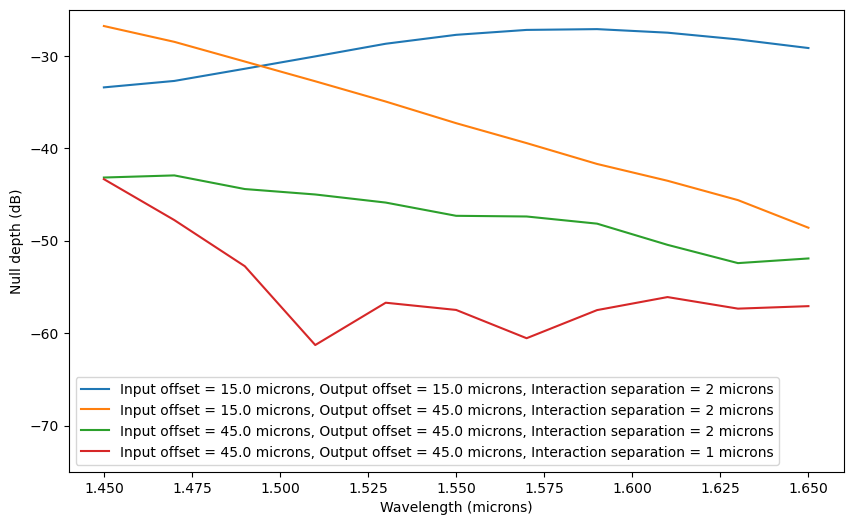

In [17]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav"
wavs = np.load(f"{save_dir}/{filename_root}_Wav.npy")

norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")

output_A, output_B, output_C = [], [], []
for wav in wavs:
    row_phase, row_A, row_B, row_C = [], [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"SbendWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    
    filename_base = os.path.basename(save_dir).split("_scan")[0]
    BendOffsetInput_0, BendOffsetOutput_0, sep_0 = 15., 15., 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_0:0.3f}".replace(".", "p"), f"{BendOffsetOutput_0:0.3f}".replace(".", "p"), f"{sep_0:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_0 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_0_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_1, BendOffsetOutput_1, sep_1 = 15., 15.*3, 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_1:0.3f}".replace(".", "p"), f"{BendOffsetOutput_1:0.3f}".replace(".", "p"), f"{sep_1:0.3f}".replace(".", "p")
    filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_1 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_1_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_2, BendOffsetOutput_2, sep_2 = 15.*3, 15.*3, 2
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_2:0.3f}".replace(".", "p"), f"{BendOffsetOutput_2:0.3f}".replace(".", "p"), f"{sep_2:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}.mon"
    sim_2 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_2_norm = np.genfromtxt(filename, skip_header=5)

    BendOffsetInput_3, BendOffsetOutput_3, sep_3 = 15.*3, 15.*3, 1
    offsetIn_str, offsetOut_str, sep_str = f"{BendOffsetInput_3:0.3f}".replace(".", "p"), f"{BendOffsetOutput_3:0.3f}".replace(".", "p"), f"{sep_3:0.3f}".replace(".", "p")
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}.mon"
    sim_3 = np.genfromtxt(filename, skip_header=5)
    filename = save_dir+f"\\{filename_base}_scan_Wav{wav_str}_BendOffsetInput{offsetIn_str}_BendOffsetOutput{offsetOut_str}_CoupleSep{sep_str}_norm.mon"
    sim_3_norm = np.genfromtxt(filename, skip_header=5)

    print(norm, sim_3_norm[-1,2])
    
    # output_A.append([sim_0[-1,1]/norm, sim_1[-1,1]/norm, sim_2[-1,1]/norm, sim_3[-1,1]/norm])
    output_B.append([sim_0[-1,2]/sim_0_norm[-1,2], sim_1[-1,2]/sim_1_norm[-1,2], sim_2[-1,2]/sim_2_norm[-1,2], sim_3[-1,2]/sim_3_norm[-1,2]])
    # output_B.append([sim_0[-1,3]/norm, sim_1[-1,3]/norm, sim_2[-1,3]/norm, sim_3[-1,3]/norm])
    # output_C.append([sim_0[-1,3]/norm, sim_1[-1,3]/norm, sim_2[-1,3]/norm, sim_3[-1,3]/norm])       
# output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
output_B = np.array(output_B)

plt.figure(figsize=(10,6))
plt.plot(wavs, 10*np.log10(output_B[:, 0]), label=f'Input offset = {BendOffsetInput_0} microns, Output offset = {BendOffsetOutput_0} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 1]), label=f'Input offset = {BendOffsetInput_1} microns, Output offset = {BendOffsetOutput_1} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 2]), label=f'Input offset = {BendOffsetInput_2} microns, Output offset = {BendOffsetOutput_2} microns, Interaction separation = 2 microns')
plt.plot(wavs, 10*np.log10(output_B[:, 3]), label=f'Input offset = {BendOffsetInput_3} microns, Output offset = {BendOffsetOutput_3} microns, Interaction separation = {sep_3} microns')
plt.ylim(-75, -25)
plt.xlabel('Wavelength (microns)')
plt.ylabel('Null depth (dB)')
plt.legend()
plt.show()

In [13]:
root_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")
root_left = 'Tricoupler_FiberOneInput_Left_scan_Wav'
root_right = 'Tricoupler_FiberOneInput_Right_scan_Wav'
root_center = 'Tricoupler_FiberOneInput_Center_scan_Wav'

wavs, outputs_left, outputs_center, outputs_right = [], [], [], []
lengths = np.load(f"{save_dir}/{filename_root}_CouplingLength.npy")
for norm_file in norm_files:
    wav_str = norm_file.split('.mon')[0].split('_Wav')[-1]
    wav = float(wav_str.replace('p', '.'))
    wavs.append(wav)
    norm_mon = np.genfromtxt(norm_file, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    
    filename_left = root_dir+f"{root_left}\\Tricoupler_FiberOneInput_Left_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_left, skip_header=5)
    outputs_left.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm])   

    filename_right = root_dir+f"{root_right}\\Tricoupler_FiberOneInput_Right_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_right, skip_header=5)
    outputs_right.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm]) 

    filename_center = root_dir+f"{root_center}\\Tricoupler_FiberOneInput_Center_scan_Wav{wav_str}.mon"
    sim = np.genfromtxt(filename_center, skip_header=5)
    outputs_center.append([sim[-1,1]/norm, sim[-1,2]/norm, sim[-1,3]/norm]) 
wavs = np.array(wavs)
inputs = [np.array(outputs_left).T, np.array(outputs_center).T, np.array(outputs_right).T]

wav_range = [1450, 1650]

fig, ax = plt.subplots(1, 3, figsize=(14,6), sharey=True)
plt.subplots_adjust(wspace=0)
for i_ind, outputs in enumerate(inputs):
    for o_ind in range(len(outputs)):
        ax[i_ind].plot(wavs*1000, outputs[o_ind], label=f'Output {chr(ord("A") + o_ind)}', color=f'C{o_ind}')    
    ax[i_ind].set_xlim(wav_range[0], wav_range[1])
    ax[i_ind].set_ylim(0, 1)
    ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
for i in range(2):
    ticks = ax[i].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
    ax[i].set_xticklabels(labels)
ax[1].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Throughput')
plt.legend()
fig.suptitle(f'Coupling length: {length} microns')
plt.show()

np.save(f"{root_dir}\\{root_left}\\{root_left}_wavs", wavs)
np.save(f"{root_dir}\\{root_left}\\{root_left}_outputs", np.array(outputs_left).T)
np.save(f"{root_dir}\\{root_center}\\{root_center}_wavs", wavs)
np.save(f"{root_dir}\\{root_center}\\{root_center}_outputs", np.array(outputs_center).T)
np.save(f"{root_dir}\\{root_right}\\{root_right}_wavs", wavs)
np.save(f"{root_dir}\\{root_right}\\{root_right}_outputs", np.array(outputs_right).T)

FileNotFoundError: C:\Users\runner\ActivePIC\Tricoupler\Tricoupler_FiberOneInput_Left_scan_Wav\Tricoupler_FiberOneInput_Left_scan_Wav1p450.mon not found.

C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


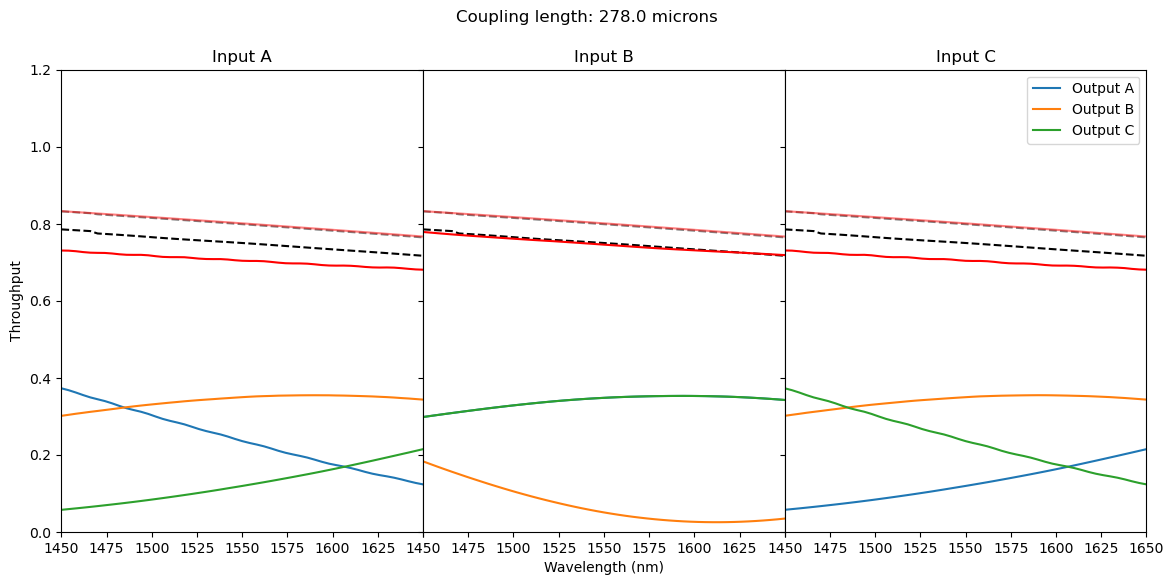

C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


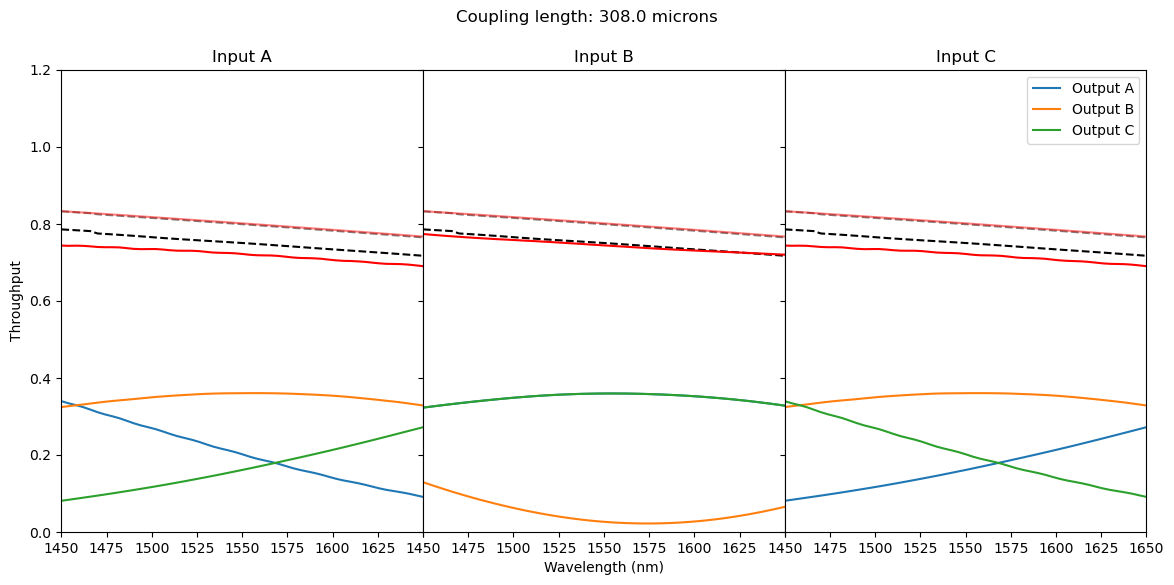

C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)
C:\Users\runner\AppData\Local\Temp\ipykernel_13300\1052987150.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(labels)


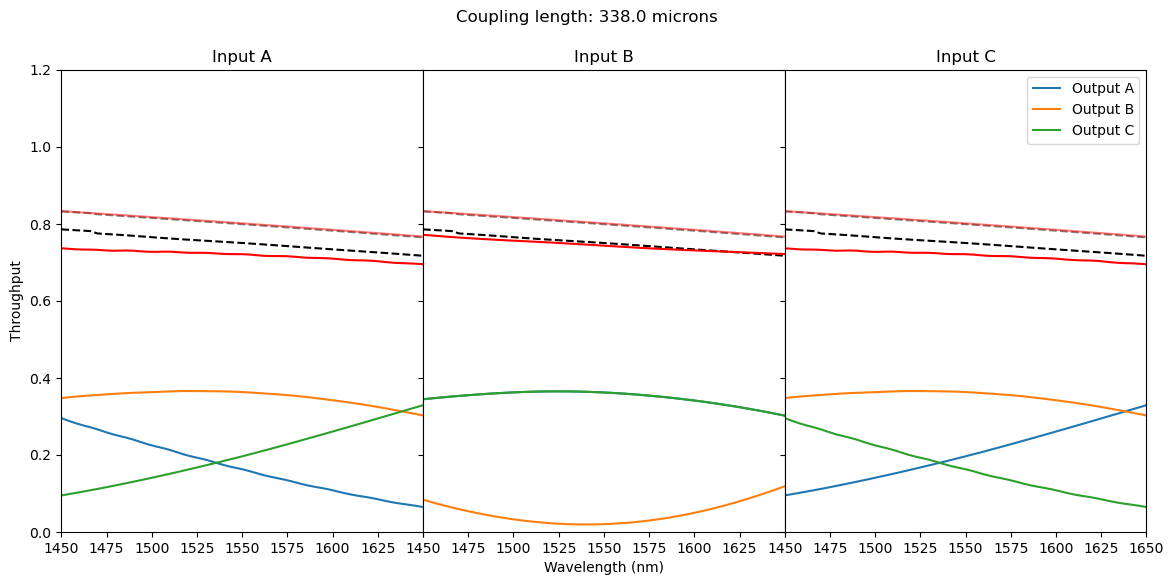

In [3]:
root_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\SbendWaveguide\\SbendWaveguide_scan_Wav\\"
norm_files = glob.glob(norm_dir+"*.mon")
sbend_str = '_CosineSbend'
root_left = f'Tricoupler_FiberOneInput_Left{sbend_str}_scan_Wav_CouplingLength'
root_right = f'Tricoupler_FiberOneInput_Right{sbend_str}_scan_Wav_CouplingLength'
root_center = f'Tricoupler_FiberOneInput_Center{sbend_str}_scan_Wav_CouplingLength'
length_arr = np.array([278., 308., 338.])

for length in length_arr:
    wavs, outputs_left, outputs_center, outputs_right = [], [], [], []
    inputs_left, inputs_center, inputs_right = [], [], []
    norms, norms_in= [], []
    length_str = f"{length:0.3f}".replace(".", "p") 
    for norm_file in norm_files:
        wav_str = norm_file.split('.mon')[0].split('_Wav')[-1]
        wav = float(wav_str.replace('p', '.'))
        wavs.append(wav)
        norm_mon = np.genfromtxt(norm_file, delimiter='', skip_header=5)
        norm, norm_in = norm_mon[-1, 1], norm_mon[0, 1]
        norms.append(norm)
        norms_in.append(norm_in)
        # print(norm)
        
        filename_left = root_dir+f"{root_left}\\Tricoupler_FiberOneInput_Left{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_left, skip_header=5)
        outputs_left.append([sim[-1,1], sim[-1,2], sim[-1,3]])   
        inputs_left.append([sim[1,1], sim[1,2], sim[1,3]])   
    
        filename_right = root_dir+f"{root_right}\\Tricoupler_FiberOneInput_Right{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_right, skip_header=5)
        outputs_right.append([sim[-1,1], sim[-1,2], sim[-1,3]])
        inputs_right.append([sim[1,1], sim[1,2], sim[1,3]])
    
        filename_center = root_dir+f"{root_center}\\Tricoupler_FiberOneInput_Center{sbend_str}_scan_Wav{wav_str}_CouplingLength{length_str}.mon"
        sim = np.genfromtxt(filename_center, skip_header=5)
        outputs_center.append([sim[-1,1], sim[-1,2], sim[-1,3]])
        inputs_center.append([sim[1,1], sim[1,2], sim[1,3]])
    wavs = np.array(wavs)
    inputs = [np.array(outputs_left).T, np.array(outputs_center).T, np.array(outputs_right).T]
    inputs_in = [np.array(inputs_left).T, np.array(inputs_center).T, np.array(inputs_right).T]
    
    wav_range = [1450, 1650]

    fig, ax = plt.subplots(1, 3, figsize=(14,6), sharey=True)
    plt.subplots_adjust(wspace=0)
    for i_ind, outputs in enumerate(inputs):
        for o_ind in range(len(outputs)):
            ax[i_ind].plot(wavs*1000, outputs[o_ind], label=f'Output {chr(ord("A") + o_ind)}', color=f'C{o_ind}')    
        ax[i_ind].plot(wavs*1000, norms, color='k', linestyle='dashed')
        ax[i_ind].plot(wavs*1000, norms_in, color='k', linestyle='dashed', alpha=0.5)
        ax[i_ind].plot(wavs*1000, np.sum(outputs, axis=0), color='r')
        ax[i_ind].plot(wavs*1000, np.sum(inputs_in[i_ind], axis=0), color='r', alpha=0.5)
        
        ax[i_ind].set_xlim(wav_range[0], wav_range[1])
        ax[i_ind].set_ylim(0, 1.2)
        ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
    for i in range(2):
        ticks = ax[i].get_xticks()
        labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
        ax[i].set_xticklabels(labels)
    ax[1].set_xlabel('Wavelength (nm)')
    ax[0].set_ylabel('Throughput')
    plt.legend()
    fig.suptitle(f'Coupling length: {length} microns')
    plt.show()
    
    np.save(f"{root_dir}\\{root_left}\\{root_left}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_left}\\{root_left}{length_str}_outputs", np.array(outputs_left).T)
    np.save(f"{root_dir}\\{root_center}\\{root_center}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_center}\\{root_center}{length_str}_outputs", np.array(outputs_center).T)
    np.save(f"{root_dir}\\{root_right}\\{root_right}{length_str}_wavs", wavs)
    np.save(f"{root_dir}\\{root_right}\\{root_right}{length_str}_outputs", np.array(outputs_right).T)

In [23]:
outputs.sum(axis=0), norm

array([0.57309549, 0.5776516 , 0.58181168, 0.58623118, 0.59039212,
       0.59812823, 0.6016518 , 0.60404405, 0.60674465, 0.60987777,
       0.61417229, 0.61832735, 0.62344167, 0.62892394, 0.63371501,
       0.63808473, 0.64252288, 0.64634733, 0.64969457, 0.65202992,
       0.65418513, 0.65634623, 0.65908197, 0.66266392, 0.66717826,
       0.67169611, 0.6762355 , 0.68036486, 0.68461002, 0.68737614,
       0.68923818, 0.69089179, 0.69279737, 0.69590343, 0.69983204,
       0.70466862, 0.70925221, 0.71373491, 0.71687833, 0.71939197,
       0.71979933, 0.72003364, 0.72102627, 0.72320245, 0.7272871 ,
       0.73308204, 0.73783988, 0.74106229, 0.74248618, 0.74235592,
       0.74237812])

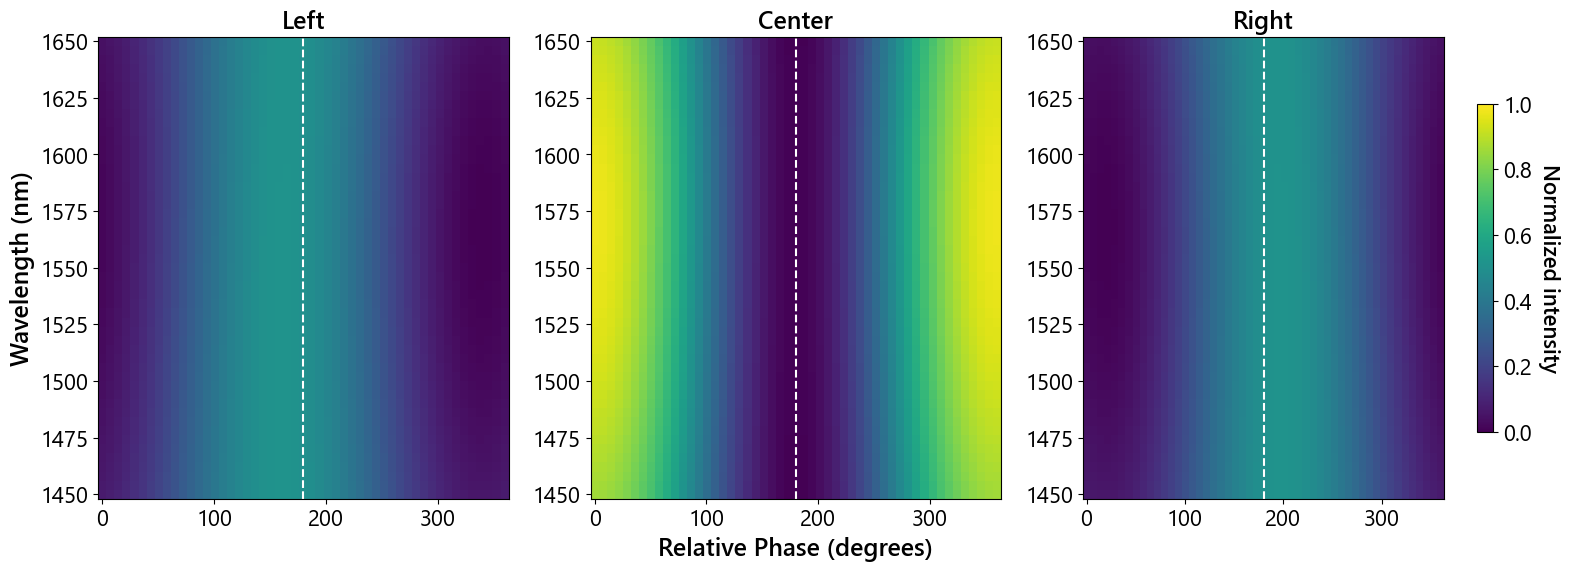

In [25]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"

filename_root = "Tricoupler_FiberTwoInput"
save_dir = working_dir+f"{filename_root}_scan_Wav_Phase"
phases = np.load(f"{save_dir}/{filename_root}_Phase.npy")
wavs = np.load(f"{save_dir}/{filename_root}_Wav.npy")

# filename_root = "Tricoupler_2Layer"
# CoupleLength, DecoupleLength = 209.44, 320.32
# save_dir = working_dir+f"{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_scan_Wav_Phase"
# phases = np.load(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Phase.npy")
# wavs = np.load(f"{save_dir}/{filename_root}_CoupleLength{str(CoupleLength).replace('.', 'p')}_DecoupleLength{str(DecoupleLength).replace('.', 'p')}_Wav.npy")

norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

output_A, output_B, output_C = [], [], []
for wav in wavs:
    row_phase, row_A, row_B, row_C = [], [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    # norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
    # norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    # norm = norm_mon[-1, 1]
    for phase in phases:
        phase_str = f"{phase:.3f}".replace('.', 'p')
        filename_base = os.path.basename(save_dir).split("_scan")[0]
        filename = save_dir+f"/{filename_base}_scan_Wav{wav_str}_Phase{phase_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1])
        row_B.append(sim[-1,2])
        row_C.append(sim[-1,3])        
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
output_tot = output_A + output_B + output_C
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(phases, wavs*1000, output_A/output_tot, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(phases, wavs*1000, output_B/output_tot, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(phases, wavs*1000, output_C/output_tot, vmin=vmin, vmax=vmax)
for i in range(3):
    # ax[i].axvline(0, linestyle='dashed', color='white')
    ax[i].axvline(180, linestyle='dashed', color='white')
ax[0].set_title('Left', fontsize=18)
ax[1].set_title('Center', fontsize=18)
ax[2].set_title('Right', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Relative Phase (degrees)", fontsize=18)
ax[0].set_ylabel("Wavelength (nm)", fontsize=18)
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_outputs.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [36]:
ind_wav = np.argmin(wavs)
null = output_B/np.max(output_B, axis=1)
10*np.log10(np.min(null, axis=1)[ind_wav])
for i, wav in enumerate(wavs):
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    print(np.max(output_B[i]/norm))

0.8570064515514118
0.8628672020367079
0.8685268710505163
0.8745975723019607
0.8813161291962355
0.8875857938786511
0.8933202561981809
0.8981957207109416
0.9026249405624881
0.9070717666258239
0.9118577439267836
0.9171118081817787
0.9226563087425299
0.9270278119900157
0.9306627666480632
0.9339540692323903
0.9368650511665638
0.9399052335722131
0.942973347637167
0.9459791118844313
0.9486450630064103
0.9504758442774253
0.9516088635759514
0.9522696922169425
0.952746383710574
0.9531705213239026
0.9537421275081572
0.9540459339446705
0.9542632978526246
0.9536772625173547
0.9525148554066691
0.951019386424843
0.949260089021243
0.9472535103874002
0.9451864352213194
0.9431589409373813
0.9405522949498502
0.9375350138572801
0.9340599712581903
0.9300788493533094
0.9257279970008546
0.9209680980737481
0.916105606559148
0.911229480158726
0.9062728682186961
0.901085522239955
0.8955795435410884
0.8896813302141657
0.8831744449939583
0.876088408070158
0.8686348911168322


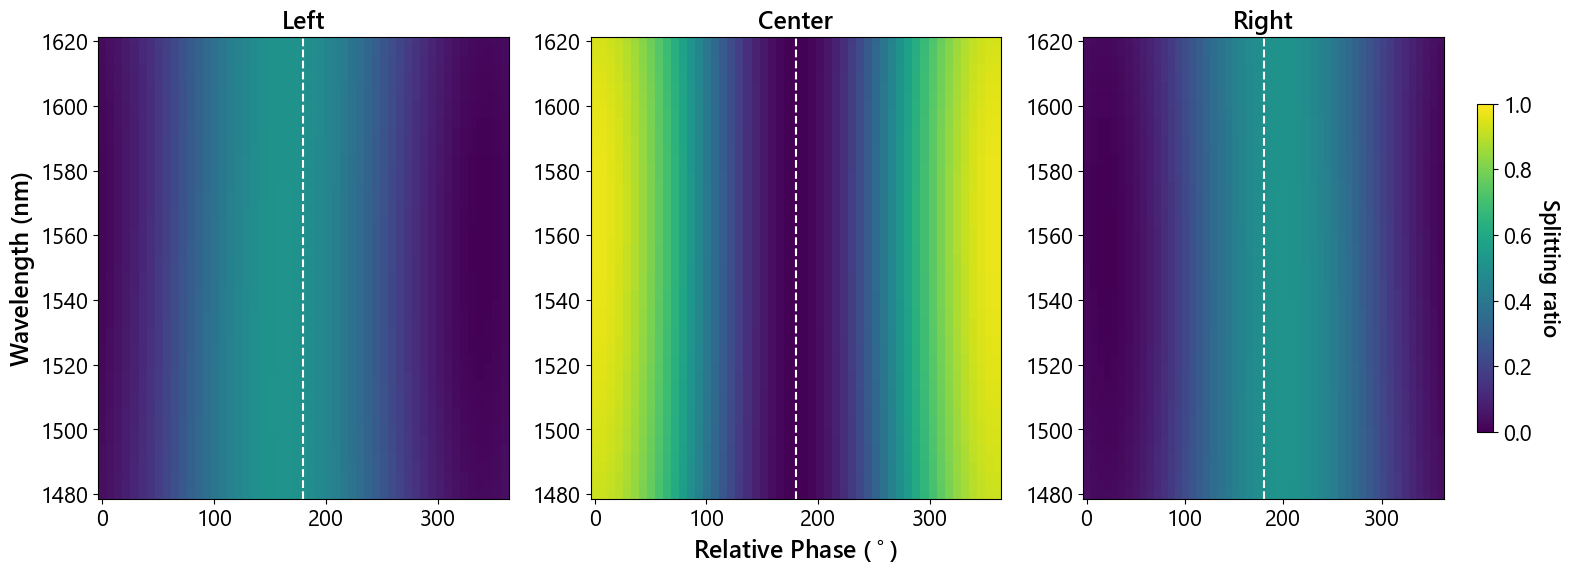

In [6]:
output_tot = output_A + output_B + output_C
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(phases, wavs*1000, output_A/output_tot, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(phases, wavs*1000, output_B/output_tot, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(phases, wavs*1000, output_C/output_tot, vmin=vmin, vmax=vmax)
for i in range(3):
    # ax[i].axvline(0, linestyle='dashed', color='white')
    ax[i].axvline(180, linestyle='dashed', color='white')
ax[0].set_title('Left', fontsize=18)
ax[1].set_title('Center', fontsize=18)
ax[2].set_title('Right', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Splitting ratio', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Relative Phase ($^\circ$)", fontsize=18)
ax[0].set_ylabel("Wavelength (nm)", fontsize=18)
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_outputs.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [8]:
np.shape(output_B)

(51, 51)

In [12]:
np.min(output_B, axis=1)

array([0.00038602, 0.0004077 , 0.00043123, 0.00045592, 0.00048121,
       0.00050741, 0.00053513, 0.00056584, 0.00060024, 0.0006373 ,
       0.00067645, 0.00071696, 0.00075888, 0.00080087, 0.00084297,
       0.00088464, 0.00092564, 0.00096494, 0.00100194, 0.00103892,
       0.00107341, 0.00110658, 0.00113807, 0.00116727, 0.00119632,
       0.00122415, 0.00124909, 0.00127093, 0.00128958, 0.00130456,
       0.0013181 , 0.00132923, 0.00133729, 0.00134147, 0.00134372,
       0.00134268, 0.00133853, 0.00133111, 0.00132054, 0.00130765,
       0.00129268, 0.00127508, 0.00125568, 0.00123345, 0.00120966,
       0.00118351, 0.00115635, 0.00112718, 0.00109752, 0.00106729,
       0.00103761])

In [21]:
np.max(output_B, axis=1)

array([0.6883095, 0.6912109, 0.6940164, 0.696763 , 0.6994057, 0.7019559,
       0.7043972, 0.706718 , 0.7088984, 0.7109343, 0.7128083, 0.7145326,
       0.7160826, 0.7174589, 0.7186586, 0.7196733, 0.7205158, 0.721167 ,
       0.721649 , 0.7219678, 0.72215  , 0.7221793, 0.722079 , 0.7218434,
       0.7215031, 0.7210366, 0.7204844, 0.7198301, 0.7190905, 0.718251 ,
       0.7173154, 0.71627  , 0.7151157, 0.7138448, 0.7124763, 0.7109835,
       0.7093846, 0.7076853, 0.7058707, 0.7039448, 0.7018949, 0.6997679,
       0.6975488, 0.695225 , 0.6928104, 0.6902916, 0.6876026, 0.6847661,
       0.6818032, 0.6787236, 0.675528 ])

In [20]:
null = np.min(output_B, axis=1)/np.max(output_B, axis=1)
10*np.log10(output_B[wavs == 1.55])

array([[ -1.4204269 ,  -1.43577398,  -1.48527432,  -1.56929505,
         -1.68852112,  -1.84424709,  -2.03828096,  -2.27214755,
         -2.54770655,  -2.86759101,  -3.2353585 ,  -3.65511747,
         -4.13199426,  -4.67283958,  -5.2862672 ,  -5.98298832,
         -6.77738725,  -7.68891197,  -8.74504746,  -9.98532396,
        -11.46978878, -13.2958167 , -15.63594343, -18.83397236,
        -23.62861851, -29.12166782, -24.20927857, -19.20751082,
        -15.89731906, -13.49377994, -11.62777521, -10.11581164,
         -8.85506445,  -7.78323178,  -6.85910629,  -6.05440459,
         -5.34914266,  -4.72840603,  -4.18108229,  -3.69838683,
         -3.27334696,  -2.90080356,  -2.57647517,  -2.29678225,
         -2.05905297,  -1.86141712,  -1.70219923,  -1.57946214,
         -1.49199553,  -1.4391191 ,  -1.4204269 ]])

In [17]:
wavs

array([1.48  , 1.4828, 1.4856, 1.4884, 1.4912, 1.494 , 1.4968, 1.4996,
       1.5024, 1.5052, 1.508 , 1.5108, 1.5136, 1.5164, 1.5192, 1.522 ,
       1.5248, 1.5276, 1.5304, 1.5332, 1.536 , 1.5388, 1.5416, 1.5444,
       1.5472, 1.55  , 1.5528, 1.5556, 1.5584, 1.5612, 1.564 , 1.5668,
       1.5696, 1.5724, 1.5752, 1.578 , 1.5808, 1.5836, 1.5864, 1.5892,
       1.592 , 1.5948, 1.5976, 1.6004, 1.6032, 1.606 , 1.6088, 1.6116,
       1.6144, 1.6172, 1.62  ])

In [90]:
throughput = 10**(exoplanet_original/10)
np.min(throughput), np.max(throughput), wavs

(0.8554024449532575,
 0.9192235826467826,
 array([1.48  , 1.4828, 1.4856, 1.4884, 1.4912, 1.494 , 1.4968, 1.4996,
        1.5024, 1.5052, 1.508 , 1.5108, 1.5136, 1.5164, 1.5192, 1.522 ,
        1.5248, 1.5276, 1.5304, 1.5332, 1.536 , 1.5388, 1.5416, 1.5444,
        1.5472, 1.55  , 1.5528, 1.5556, 1.5584, 1.5612, 1.564 , 1.5668,
        1.5696, 1.5724, 1.5752, 1.578 , 1.5808, 1.5836, 1.5864, 1.5892,
        1.592 , 1.5948, 1.5976, 1.6004, 1.6032, 1.606 , 1.6088, 1.6116,
        1.6144, 1.6172, 1.62  ]))

Plot null depth

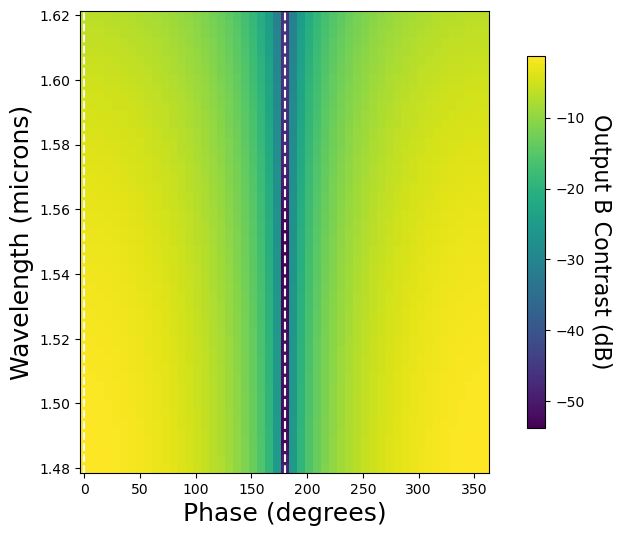

In [64]:
contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, contrast)
plt.axvline(0, linestyle='dashed', color='white')
plt.axvline(180, linestyle='dashed', color='white')
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Output B Contrast (dB)', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

In [65]:
ind = np.argmin(output_B)
row_min, col_min = np.unravel_index(ind, np.shape(output_B))
ind = np.argmax(output_B)
row_max, col_max = np.unravel_index(ind, np.shape(output_B))
print(f'Null depth: {10*np.log10(np.min(output_B)):0.2f} dB at wavelength = {wavs[row_min]} microns, phase shift = {phases[col_min]}')
print(f'Exoplanet throughput: {np.max(output_B)*100:0.2f}% at wavelength = {wavs[row_max]} microns, phase shift = {phases[col_max]}')

Null depth: -53.78 dB at wavelength = 1.5472000000000001 microns, phase shift = 180.0
Exoplanet throughput: 75.11% at wavelength = 1.48 microns, phase shift = 0.0


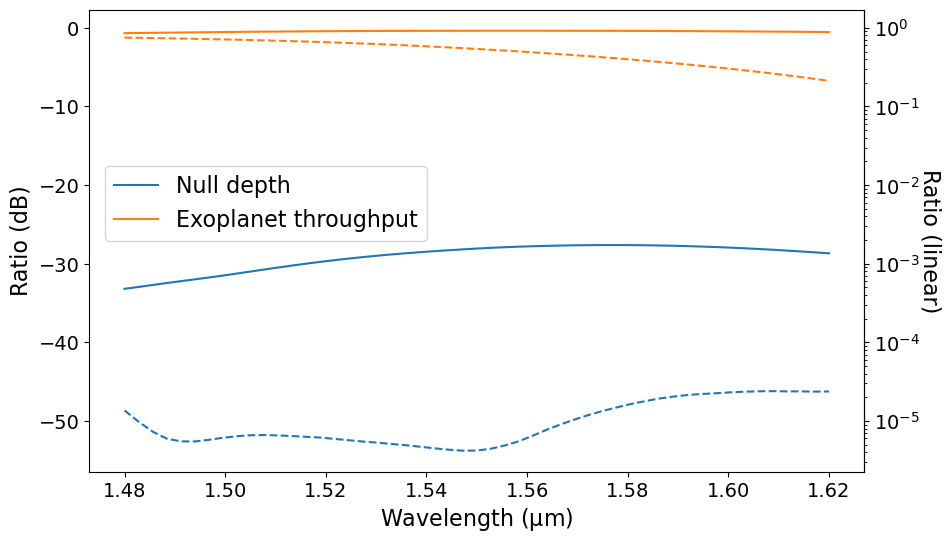

In [83]:
def db_to_linear(db):
    return 10 ** (db / 10)

def linear_to_db(lin):
    return 10 * np.log10(lin)

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(wavs_original, null_original, color='C0', label='Null depth')
ax.plot(wavs_original, exoplanet_original, color='C1', label='Exoplanet throughput')
ax.plot(wavs_2Layer, null_2Layer, color='C0', linestyle='dashed')
ax.plot(wavs_2Layer, exoplanet_2Layer, color='C1', linestyle='dashed')

# Secondary axis
ax_lin = ax.secondary_yaxis(
    'right',
    functions=(db_to_linear, linear_to_db)
)
ax_lin.set_ylabel("Ratio (linear)", fontsize=16, rotation=270, labelpad=15)
ax_lin.set_yscale('log')

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
ax_lin.tick_params(axis='y', labelsize=14)
plt.xlabel('Wavelength ($\mathrm{\mu}$m)', fontsize=16)
plt.ylabel('Ratio (dB)', fontsize=16)
plt.legend(fontsize=16, loc=(0.02, 0.5))
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_nullChromaticity.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [67]:
null_2Layer = np.copy(contrast[:, np.argwhere(phases==180)].flatten())
exoplanet_2Layer = np.copy(contrast[:, np.argwhere(phases==0)].flatten())
wavs_2Layer = np.copy(wavs)

Plot throughput

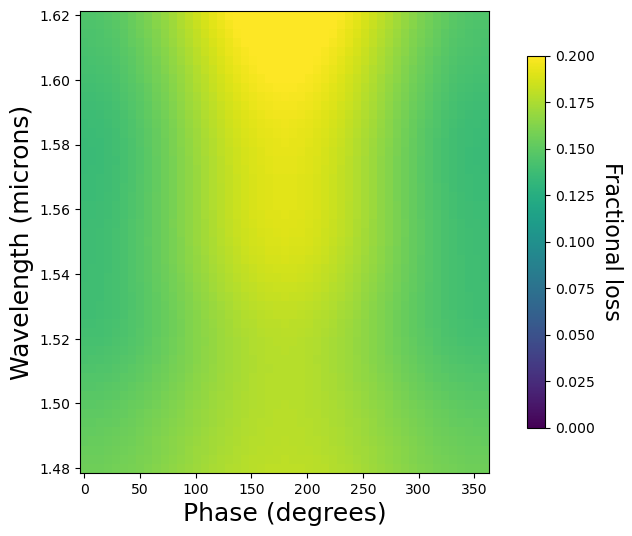

In [7]:
vmin, vmax = 0, 0.2
fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, 1 - (output_A+output_B+output_C), vmin=vmin, vmax=vmax)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Fractional loss', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

In [8]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
filename_root = f"Tricoupler_2Layer_wav{wav_str}_phase{phase_str}"
save_dir = working_dir+f"{filename_root}_scan_CoupleLength_DecoupleLength"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

coupleLengths = np.load(f"{save_dir}/{filename_root}_CoupleLength.npy")
decoupleLengths = np.load(f"{save_dir}/{filename_root}_DecoupleLength.npy")
coupleLength2 = 308
coupleLength2_str = f"{coupleLength2:.3f}".replace('.', 'p')

output_A, output_B, output_C = [], [], []
for coupleLength in coupleLengths:
    row_phase, row_A, row_B, row_C = [], [], [], []
    coupleLength_str = f"{coupleLength:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{f'{wav:.3f}'.replace('.', 'p')}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    for decoupleLength in decoupleLengths:
        decoupleLength_str = f"{decoupleLength:.3f}".replace('.', 'p')
        filename = save_dir+f"\\{filename_root}_scan_CoupleLength{coupleLength_str}_DecoupleLength{decoupleLength_str}_CoupleLength2{coupleLength_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1]/norm)
        row_B.append(sim[-1,2]/norm)
        row_C.append(sim[-1,3]/norm)        
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(decoupleLengths, coupleLengths, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(decoupleLengths, coupleLengths, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(decoupleLengths, coupleLengths, output_C, vmin=vmin, vmax=vmax)
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Decouple Length (microns)", fontsize=18)
ax[0].set_ylabel(f"Couple Length (microns)", fontsize=18)
plt.show()

contrast = 10*np.log10(output_B/(output_A + output_C))

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
plt.show()

FileNotFoundError: C:\\Users\\runner\\ActivePIC\\Tricoupler\\Tricoupler_2Layer_wav1p55_phase180_scan_CoupleLength_DecoupleLength\Tricoupler_2Layer_wav1p55_phase180_scan_CoupleLength154p000_DecoupleLength154p000_CoupleLength2154p000.mon not found.

# Optimize multilayer tricoupler specs

In [2]:
working_dir = "C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
filename_root = "Tricoupler_2Layer"
wav, phase = 1.55, 0
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
save_dir = working_dir+f"{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength_DecoupleLength"
filename = f"{filename_root}.ind"

coupleLength_arr = np.linspace(0.5*308, 1.5*308, 51)
decoupleLength_arr = np.linspace(0.5*308, 1.5*308, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for coupleLength in tqdm(coupleLength_arr, desc='Couple length loop', position=0, leave=False):
    for decoupleLength in tqdm(decoupleLength_arr, desc=f"Decouple length loop (Couple length: {coupleLength} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.set_symbol("TricouplerCoupleLength", coupleLength)
        c.set_symbol("TricouplerDecoupleLength", decoupleLength)
        c.write(working_dir+filename)

        couple_str = f"{coupleLength:0.3f}".replace(".", "p")
        decouple_str = f"{decoupleLength:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{filename_root}_wav{wav_str}_phase{phase_str}_scan_CoupleLength{couple_str}_DecoupleLength{decouple_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f"{save_dir}/{filename_root}_CoupleLength.npy", coupleLength_arr)
np.save(f"{save_dir}/{filename_root}_DecoupleLength.npy", decoupleLength_arr)

NameError: name 'np' is not defined

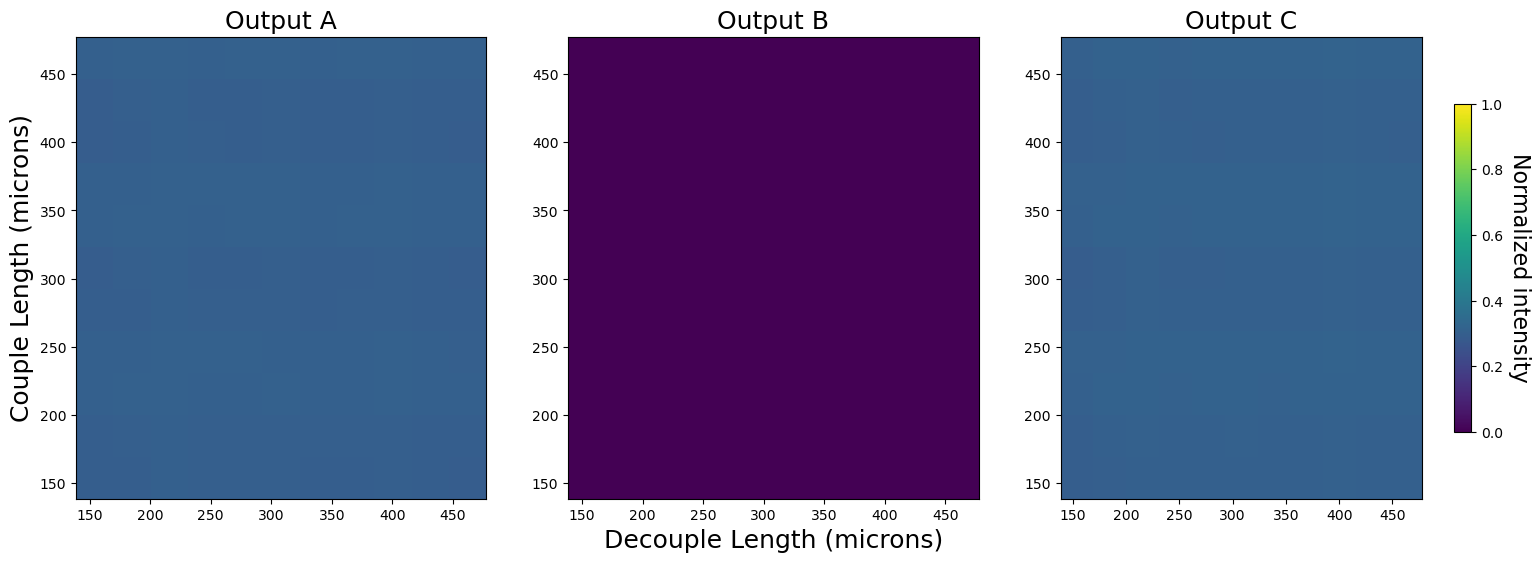

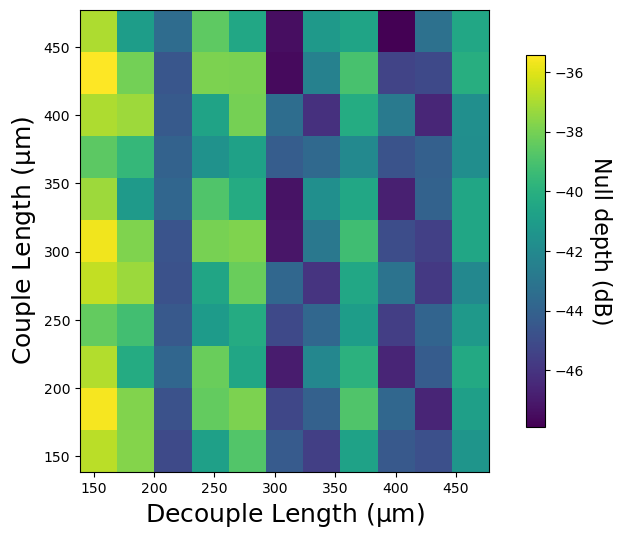

In [ ]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Tricoupler\\"
wav, phase = 1.55, 180
wav_str, phase_str = str(wav).replace('.', 'p'), str(phase).replace('.', 'p')
filename_root = f"Tricoupler_2Layer_wav{wav_str}_phase{phase_str}"
save_dir = working_dir+f"{filename_root}_scan_CoupleLength_DecoupleLength_CoupleLength2"

coupleLengths = np.load(f"{save_dir}/Tricoupler_2Layer_CoupleLength.npy")
decoupleLengths = np.load(f"{save_dir}/Tricoupler_2Layer_DecoupleLength.npy")
coupleLengths2 = np.load(f"{save_dir}/Tricoupler_2Layer_CoupleLength2.npy")

outputs_A, outputs_B, outputs_C = [], [], []
for coupleLength in coupleLengths:
    coupleLength_str = f"{coupleLength:.3f}".replace('.', 'p')
    output_A, output_B, output_C = [], [], []
    for decoupleLength in decoupleLengths:
        decoupleLength_str = f"{decoupleLength:.3f}".replace('.', 'p')
        row_A, row_B, row_C = [], [], []
        for coupleLength2 in coupleLengths:
            coupleLength2_str = f"{coupleLength2:.3f}".replace('.', 'p')
            filename = save_dir+f"\\{filename_root}_scan_CoupleLength{coupleLength_str}_DecoupleLength{decoupleLength_str}_CoupleLength2{coupleLength2_str}.mon"
            sim = np.genfromtxt(filename, skip_header=5)
            row_A.append(sim[-1,1])#/norm)
            row_B.append(sim[-1,2])#/norm)
            row_C.append(sim[-1,3])#/norm)        
        output_A.append(row_A)
        output_B.append(row_B)
        output_C.append(row_C)
    outputs_A.append(output_A)
    outputs_B.append(output_B)
    outputs_C.append(output_C)
outputs_A, outputs_B, outputs_C = np.array(outputs_A), np.array(outputs_B), np.array(outputs_C)

vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(decoupleLengths, coupleLengths, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(decoupleLengths, coupleLengths, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(decoupleLengths, coupleLengths, output_C, vmin=vmin, vmax=vmax)
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Decouple Length (microns)", fontsize=18)
ax[0].set_ylabel(f"Couple Length (microns)", fontsize=18)
plt.show()

contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
# plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_parameterSearch.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

Plot null depth

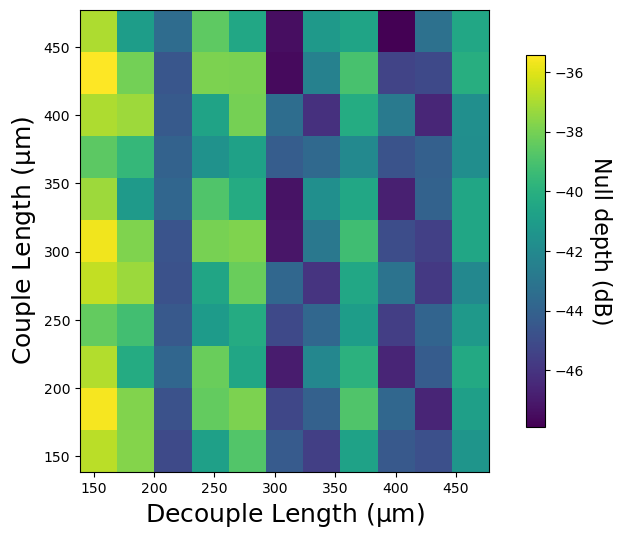

In [ ]:
contrast = 10*np.log10(output_B)

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(decoupleLengths, coupleLengths, contrast)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=20, fontsize=16)
ax.set_xlabel("Decouple Length ($\mathrm{\mu}$m)", fontsize=18)
ax.set_ylabel("Couple Length ($\mathrm{\mu}$m)", fontsize=18)
plt.savefig('C:\\Users\\runner\\ActivePIC\\SoL_figs\\Tricoupler_2Layer_parameterSearch.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
10*np.log10(output_B[row_max, col_max])

-36.495412269005286

In [ ]:
ind = np.argmin(output_B)
row_min, col_min = np.unravel_index(ind, np.shape(output_B))
print(f'Null depth: {10*np.log10(np.min(output_B)):0.2f} dB at couple length = {coupleLengths[row_min]} microns, decouple length = {decoupleLengths[col_min]} microns')

Null depth: -53.75 dB at couple length = 209.44 microns, decouple = 320.32 microns


In [ ]:
ind = np.argmax(output_B)
row_max, col_max = np.unravel_index(ind, np.shape(output_B))
print(f'Exoplanet throughput: {np.max(output_B)*100:0.2f}% at couple length = {coupleLengths[row_max]} microns, decouple length = {decoupleLengths[col_max]} microns')

Exoplanet throughput: 78.36% at couple length = 154.0 microns, decouple = 190.96 microns


Plot throughput

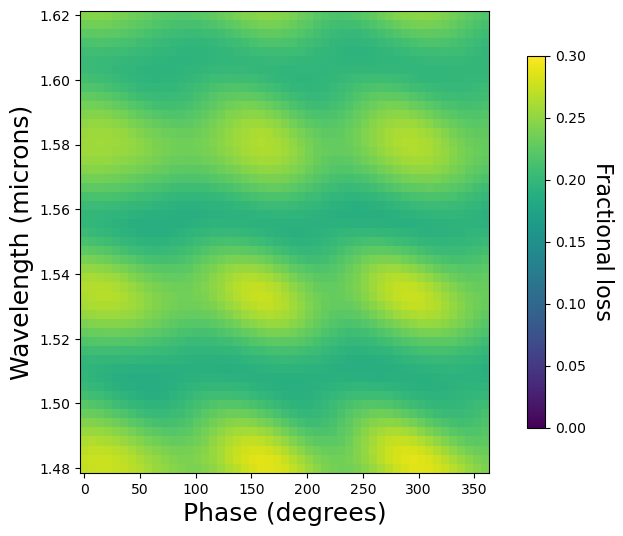

In [ ]:
vmin, vmax = 0, 0.3
fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases, wavs, 1 - (output_A+output_B+output_C), vmin=vmin, vmax=vmax)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Fractional loss', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()